## Machine Learning for House Price and Condition Predictions

# loading Ames Housing dataset and first 10 records

In [2]:
# References
# Dataset: De Cock, D. (2011). https://doi.org/10.1080/10691898.2011.11889627
# pandas read_csv: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
# pandas head: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html

from pathlib import Path
import pandas as pd
from IPython.display import display

project_folder = Path(
    r"C:\Users\nyamb\OneDrive\Desktop\Data Science\CS 746 Pespectives on Data Science\Project"
)

housingData = pd.read_csv(project_folder / "AmesHousing.csv")

print("Object type:", type(housingData).__name__)
display(housingData.head(10))

Object type: DataFrame


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
5,6,527105030,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,195500
6,7,527127150,120,RL,41.0,4920,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,213500
7,8,527145080,120,RL,43.0,5005,Pave,NaN,IR1,HLS,...,0,NaN,NaN,NaN,0,1,2010,WD,Normal,191500
8,9,527146030,120,RL,39.0,5389,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,3,2010,WD,Normal,236500
9,10,527162130,60,RL,60.0,7500,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,189000


# Showing dimensions, column names, their datatypes, and variables. 

In [3]:
# References
# pandas shape: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html
# pandas dtypes: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dtypes.html
# pandas drop: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt

number_of_rows, number_of_columns = housingData.shape
print("Total rows:", number_of_rows)
print("Total columns:", number_of_columns)

price_target = "SalePrice"
identifier_columns = ["Order", "PID"]

# Identifying candidate predictors (independent variables) for the price model.
price_predictors = housingData.drop(
    columns=identifier_columns + [price_target]
).columns.tolist()

print("Price target:", price_target)  #dependent variable which is the value we want to predict. 
print("Candidate predictors:", len(price_predictors))

column_summary = housingData.dtypes.astype(str).rename("Data Type").to_frame()
column_summary["Role for Price Prediction"] = "Candidate predictor"
column_summary.loc[identifier_columns, "Role for Price Prediction"] = "Identifier"
column_summary.loc[price_target, "Role for Price Prediction"] = "Target"

# Display the name, data type, and role of all 82 columns.
with pd.option_context("display.max_rows", None):
    display(column_summary)

Total rows: 2930
Total columns: 82
Price target: SalePrice
Candidate predictors: 79


,Data Type,Role for Price Prediction
Order,int64,Identifier
PID,int64,Identifier
MS SubClass,int64,Candidate predictor
MS Zoning,str,Candidate predictor
Lot Frontage,float64,Candidate predictor
Lot Area,int64,Candidate predictor
Street,str,Candidate predictor
Alley,str,Candidate predictor
Lot Shape,str,Candidate predictor
Land Contour,str,Candidate predictor


Explanation: 
The output shows SalesPrice as the target which is the value we want to predict. 
Here we have 79 indepedent variables , and two identifiers(Order and PID)
The entire Ames Housing dataset has 2930 rows and 82 columns. 

# Generationg descriptive statistics

In [4]:
# References
# pandas describe: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html
# pandas select_dtypes: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.select_dtypes.html

numeric_data = housingData.select_dtypes(include="number").drop(
    columns=identifier_columns
)
text_data = housingData.select_dtypes(exclude="number").drop(
    columns=identifier_columns, errors="ignore"
)

print("Descriptive statistics for numeric columns")
display(numeric_data.describe().T.round(2))

print("Descriptive statistics for text columns")
display(text_data.describe().T)

Descriptive statistics for numeric columns


,count,mean,std,min,25%,50%,75%,max
MS SubClass,2930.0,57.39,42.64,20.0,20.00,50.0,70.00,190.0
Lot Frontage,2440.0,69.22,23.37,21.0,58.00,68.0,80.00,313.0
Lot Area,2930.0,10147.92,7880.02,1300.0,7440.25,9436.5,11555.25,215245.0
Overall Qual,2930.0,6.09,1.41,1.0,5.00,6.0,7.00,10.0
Overall Cond,2930.0,5.56,1.11,1.0,5.00,5.0,6.00,9.0
Year Built,2930.0,1971.36,30.25,1872.0,1954.00,1973.0,2001.00,2010.0
Year Remod/Add,2930.0,1984.27,20.86,1950.0,1965.00,1993.0,2004.00,2010.0
Mas Vnr Area,2907.0,101.90,179.11,0.0,0.00,0.0,164.00,1600.0
BsmtFin SF 1,2929.0,442.63,455.59,0.0,0.00,370.0,734.00,5644.0
BsmtFin SF 2,2929.0,49.72,169.17,0.0,0.00,0.0,0.00,1526.0


Descriptive statistics for text columns


,count,unique,top,freq
MS Zoning,2930,7,RL,2273
Street,2930,2,Pave,2918
Alley,198,2,Grvl,120
Lot Shape,2930,4,Reg,1859
Land Contour,2930,4,Lvl,2633
Utilities,2930,3,AllPub,2927
Lot Config,2930,5,Inside,2140
Land Slope,2930,3,Gtl,2789
Neighborhood,2930,28,NAmes,443
Condition 1,2930,9,Norm,2522


Explanation:
We created two desriptive tables one for numeric columns and the other for text columns. 
Numeric table shows non missing count, mean, standard deviation, minimum, quartiles, and maximum. 
Text table issues the non missing count, number of unique values, most frequent value, and its frequency. 

# Counting missing values and checking for  duplicates. 

In [5]:
# References
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
# pandas duplicated: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html

# Count missing values in every column, including columns with zero missing.
missing_counts = housingData.isna().sum().sort_values(ascending=False)

with pd.option_context("display.max_rows", None):
    display(missing_counts.rename("Missing Values").to_frame())

print("Columns with missing values:", (missing_counts > 0).sum())

# Counting exact duplicates across all columns.
print("Exact duplicate rows:", housingData.duplicated().sum())

# Checking for repeated observations even when record identifiers differ.
print("Duplicate rows excluding identifiers:",
    housingData.drop(columns=identifier_columns).duplicated().sum()
)

,Missing Values
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Qual,159
Garage Yr Blt,159
Garage Cond,159


Columns with missing values: 27
Exact duplicate rows: 0
Duplicate rows excluding identifiers: 0


Explanation
We have 27 columns with missing values and no duplicate rows even after excluding Order and PID. 
No need to drop rows because of missing targets. 

# Displaying 5 SalePrice statistics. 

In [6]:
# References
# pandas agg: https://pandas.pydata.org/docs/reference/api/pandas.Series.agg.html
# pandas std: https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html

price_statistics = housingData[price_target].agg(
    ["min", "max", "mean", "median", "std"]
)

price_statistics.index = [
    "Minimum", "Maximum", "Mean", "Median", "Sample standard deviation"
]

display(price_statistics.to_frame("SalePrice (USD)").round(2))

,SalePrice (USD)
Minimum,12789.00
Maximum,755000.00
Mean,180796.06
Median,160000.00
Sample standard deviation,79886.69


# Recording of confirmed feature absenses. 

In [7]:
# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas copy: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.copy.html
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
# pandas loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html

# Creating a working copy for cleaning.
housingClean = housingData.copy()

# Finding blanks that are explained by the absence of a feature.
no_pool = housingClean["Pool QC"].isna() & housingClean["Pool Area"].eq(0)
no_fireplace = (
    housingClean["Fireplace Qu"].isna() & housingClean["Fireplaces"].eq(0)
)

# Labeling only those blanks. Keeping existing ratings as recorded.
housingClean.loc[no_pool, "Pool QC"] = "No Pool"
housingClean.loc[no_fireplace, "Fireplace Qu"] = "No Fireplace"

# Checking how many blanks were resolved and how many still need review.
print("Pool QC blanks labeled No Pool:", no_pool.sum())
print("Fireplace Qu blanks labeled No Fireplace:", no_fireplace.sum())

display(
    housingClean[["Pool QC", "Fireplace Qu"]]
    .isna()
    .sum()
    .rename("Remaining Missing Values")
    .to_frame()
)

Pool QC blanks labeled No Pool: 2917
Fireplace Qu blanks labeled No Fireplace: 1422


,Remaining Missing Values
Pool QC,0
Fireplace Qu,0


In [8]:
# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
# pandas eq: https://pandas.pydata.org/docs/reference/api/pandas.Series.eq.html

garage_columns = [
    "Garage Type", "Garage Yr Blt", "Garage Finish",
    "Garage Cars", "Garage Area", "Garage Qual", "Garage Cond"
]

basement_columns = [
    "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure",
    "BsmtFin Type 1", "BsmtFin SF 1",
    "BsmtFin Type 2", "BsmtFin SF 2", "Bsmt Unf SF",
    "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"
]

# Using recorded measurements to identify properties without each feature.
no_garage = housingClean["Garage Cars"].eq(0) & housingClean["Garage Area"].eq(0)
no_basement = housingClean["Total Bsmt SF"].eq(0)

for feature, columns, absent in [
    ("Garage", garage_columns, no_garage),
    ("Basement", basement_columns, no_basement),
]:
    total_missing = housingClean[columns].isna().sum()
    missing_when_absent = housingClean.loc[absent, columns].isna().sum()

    print(f"\n{feature} audit")
    print("Properties with confirmed absence:", absent.sum())

    display(pd.DataFrame({
        "Total missing": total_missing,
        "Missing when feature is absent": missing_when_absent,
        "Missing requiring review": total_missing - missing_when_absent
    }))


Garage audit
Properties with confirmed absence: 157


,Total missing,Missing when feature is absent,Missing requiring review
Garage Type,157,157,0
Garage Yr Blt,159,157,2
Garage Finish,159,157,2
Garage Cars,1,0,1
Garage Area,1,0,1
Garage Qual,159,157,2
Garage Cond,159,157,2



Basement audit
Properties with confirmed absence: 79


,Total missing,Missing when feature is absent,Missing requiring review
Bsmt Qual,80,79,1
Bsmt Cond,80,79,1
Bsmt Exposure,83,79,4
BsmtFin Type 1,80,79,1
BsmtFin SF 1,1,0,1
BsmtFin Type 2,81,79,2
BsmtFin SF 2,1,0,1
Bsmt Unf SF,1,0,1
Total Bsmt SF,1,0,1
Bsmt Full Bath,2,1,1


Explanation:
There are 157 homes with no garage and 79 homes with no basement. 
Therefore, we can label the missing categories for those homes and fill the 2 missing basement 
bathroom counts where the recorded baseemnt area is zero. 

In [9]:
# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html

garage_categories = ["Garage Type", "Garage Finish", "Garage Qual", "Garage Cond"]

basement_categories = [
    "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure",
    "BsmtFin Type 1", "BsmtFin Type 2"
]

# Labeling missing garage categories for homes with confirmed garage absence.
for column in garage_categories:
    missing_when_absent = no_garage & housingClean[column].isna()
    housingClean.loc[missing_when_absent, column] = "No Garage"

# Labeling missing basement categories for homes with zero basement area.
for column in basement_categories:
    missing_when_absent = no_basement & housingClean[column].isna()
    housingClean.loc[missing_when_absent, column] = "No Basement"

# A home without a basement has zero basement bathrooms.
for column in ["Bsmt Full Bath", "Bsmt Half Bath"]:
    missing_when_absent = no_basement & housingClean[column].isna()
    housingClean.loc[missing_when_absent, column] = 0

# Reporting remaining blanks across the audited fields.
remaining_missing = housingClean[garage_columns + basement_columns].isna().sum()
display(remaining_missing.rename("Remaining Missing Values").to_frame())

,Remaining Missing Values
Garage Type,0
Garage Yr Blt,159
Garage Finish,2
Garage Cars,1
Garage Area,1
Garage Qual,2
Garage Cond,2
Bsmt Qual,1
Bsmt Cond,1
Bsmt Exposure,4


Explanation:
Garage Type now has 0 blanks. Garage Finish, Garage Qual, and Garage Cond each have 2 missing values. 
Bsmt Full Bath and Bsmt Half Bath have 1 missing value each
Garage Yr Blt still shows 159 blanks. Garage construction year does not apply for 157 of those homes. 


In [10]:
#inspectiong remaining garage and basement blanks. 
# We will know the affected properties and thier related measurements and this 
# will help in deciding a value is unknown or the feature is absent. 


# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
# pandas any: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.any.html
# pandas loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html

garage_numeric = ["Garage Yr Blt", "Garage Cars", "Garage Area"]

basement_numeric = [
    "Total Bsmt SF", "BsmtFin SF 1", "BsmtFin SF 2",
    "Bsmt Unf SF", "Bsmt Full Bath", "Bsmt Half Bath"
]

# Reviewing missing garage years only where a garage may be present.
# Reviewing missing garage capacity or area wherever either is blank.
missing_garage_numeric = (
    housingClean[["Garage Cars", "Garage Area"]].isna().any(axis=1)
    | (housingClean["Garage Yr Blt"].isna() & ~no_garage)
)

# Selecting properties with at least one missing numeric basement field.
missing_basement_numeric = housingClean[basement_numeric].isna().any(axis=1)

print("Properties with garage measurements to review:", missing_garage_numeric.sum())
display(
    housingClean.loc[
        missing_garage_numeric,
        ["Order", "PID", "Year Built", "Garage Type"] + garage_numeric
    ]
)

print("Properties with basement measurements to review:", missing_basement_numeric.sum())
display(
    housingClean.loc[
        missing_basement_numeric,
        ["Order", "PID", "Bsmt Qual", "Bsmt Cond"] + basement_numeric
    ]
)

Properties with garage measurements to review: 2


,Order,PID,Year Built,Garage Type,Garage Yr Blt,Garage Cars,Garage Area
1356,1357,903426160,1910,Detchd,NaN,1.0,360.0
2236,2237,910201180,1923,Detchd,NaN,NaN,NaN


Properties with basement measurements to review: 1


,Order,PID,Bsmt Qual,Bsmt Cond,Total Bsmt SF,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Bsmt Full Bath,Bsmt Half Bath
1341,1342,903230120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


From the results above, we will leave the missing measurements for the 3 records as NaN at the moment
since the audits give us enough information to keep the rows, but the missing measurements
can not be recovered from the values shown. 
For Order 1357, a detached garage has 1 recorded space and 360 square feet. We keep the measurements and leave 
garage construction year missing. Year Built refers to the house. 

For Order 2237, we leave all the 3 numerics missing and keep Detchd. The recorded garage type is detached. 
Its year, capacity, and area are missing. 

For 1342, the basement area, ratings, and bathroom counts are all missing. We leave them that way. 
There being no recorded zero area or another confirming value, we can not classify the property as having no basement. 

Therefore, no cleaning is needed for he above three rows at this step. 


In [11]:
# Checking the 2 masonry veneer fields 

# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.Series.isna.html
# pandas loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html

veneer_type_missing = housingClean["Mas Vnr Type"].isna()
veneer_area = housingClean["Mas Vnr Area"]

print("Missing veneer type with zero area:",
      (veneer_type_missing & veneer_area.eq(0)).sum())
print("Missing veneer type with positive area:",
      (veneer_type_missing & veneer_area.gt(0)).sum())
print("Missing veneer type with missing area:",
      (veneer_type_missing & veneer_area.isna()).sum())

# Inspect cases with a missing area or a positive area but no recorded type.
veneer_needs_review = veneer_area.isna() | (
    veneer_type_missing & veneer_area.gt(0)
)

display(
    housingClean.loc[
        veneer_needs_review,
        ["Order", "PID", "Mas Vnr Type", "Mas Vnr Area"]
    ]
)

Missing veneer type with zero area: 1745
Missing veneer type with positive area: 7
Missing veneer type with missing area: 23


,Order,PID,Mas Vnr Type,Mas Vnr Area
55,56,528240070,NaN,NaN
363,364,527166010,NaN,344.0
403,404,527451110,NaN,312.0
441,442,528138010,NaN,285.0
484,485,528275160,NaN,NaN
517,518,528458020,NaN,NaN
538,539,531371050,NaN,NaN
867,868,907260030,NaN,NaN
1095,1096,528290090,NaN,NaN
1119,1120,528439010,NaN,NaN


Mas Vnr Type has 1,775 balnks, while Mas Vnr Areaa has 23.  We label the 1745 misssing with zero area
with "No Vaneer"
For the 7 missing types with positive area, keep thie recorded area. The vaneer material is unknown. 
For the 23 rows with both fields missing, we leave both fields missing because we can't infer whether veneer was present. 

In [12]:
# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.Series.isna.html
# pandas loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html

# A recorded zero area supports labeling a blank type as "No Veneer".
no_veneer = (
    housingClean["Mas Vnr Type"].isna()
    & housingClean["Mas Vnr Area"].eq(0)
)

housingClean.loc[no_veneer, "Mas Vnr Type"] = "No Veneer"

print("Veneer type blanks labeled No Veneer:", no_veneer.sum())

display(
    housingClean[["Mas Vnr Type", "Mas Vnr Area"]]
    .isna()
    .sum()
    .rename("Remaining Missing Values")
    .to_frame()
)

Veneer type blanks labeled No Veneer: 1745


,Remaining Missing Values
Mas Vnr Type,30
Mas Vnr Area,23


We now have 1745 replacements. Mas Vnr Type now has 30 blanksn and Mas Vnr Area has 23. 


In [13]:
# Alley, Fence, and Misc Feature

# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas fillna: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html

absence_labels = {
    "Alley": "No Alley Access",
    "Fence": "No Fence",
    "Misc Feature": "No Misc Feature",
}

columns_to_clean = list(absence_labels)
missing_before = housingClean[columns_to_clean].isna().sum()

# Replacing blanks with the absence categories documented by Ames.
housingClean[columns_to_clean] = housingClean[columns_to_clean].fillna(
    absence_labels
)

missing_after = housingClean[columns_to_clean].isna().sum()

display(pd.DataFrame({
    "Blanks Replaced": missing_before - missing_after,
    "Remaining Missing Values": missing_after,
}))

,Blanks Replaced,Remaining Missing Values
Alley,2732,0
Fence,2358,0
Misc Feature,2824,0


In [14]:
# reviewing Lot Frontage and Electrical 

# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas groupby: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html
# pandas isna: https://pandas.pydata.org/docs/reference/api/pandas.Series.isna.html
# pandas loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html

print("Missing Lot Frontage:", housingClean["Lot Frontage"].isna().sum())
print("Missing Electrical:", housingClean["Electrical"].isna().sum())

# Compare the number of recorded frontage measurements across neighborhoods.
frontage_summary = (
    housingClean.groupby("Neighborhood")["Lot Frontage"]
    .agg(total_homes="size", recorded_frontage="count")
)

frontage_summary["missing_frontage"] = (
    frontage_summary["total_homes"] - frontage_summary["recorded_frontage"]
)

display(frontage_summary.sort_values("missing_frontage", ascending=False))

# Inspect the property with the missing electrical system category.
display(
    housingClean.loc[
        housingClean["Electrical"].isna(),
        ["Order", "PID", "Neighborhood", "Year Built", "Electrical"]
    ]
)


Missing Lot Frontage: 490
Missing Electrical: 1


,total_homes,recorded_frontage,missing_frontage
Neighborhood,,,
NAmes,443,375,68
Gilbert,165,111,54
Sawyer,151,98,53
CollgCr,267,220,47
NWAmes,131,85,46
Mitchel,114,90,24
ClearCr,44,20,24
Somerst,182,162,20
Crawfor,103,83,20


,Order,PID,Neighborhood,Year Built,Electrical
1577,1578,916386080,Timber,2006,NaN


I the output above, we have 490 missing values and 1 missing electrical value. 
We leave them as Nan for now 
We may use neighborhood medians to fill frontange later in the project and we will calculate them 
from the training set alone. The same thing may happen to Electrical using the most frequent category. 

Note: Some missing values need to be taken care off such as the Lot Frontage, Electrical, and the unresolved garage, 
basement  and vaneer measurements. A decision will be reached on how well to handle them after the split. 
Any replacement values such as medians calculated from the data will only come from the training set. 


# Creating the Condition categories and splitting the data into training and test sets. 
we shall use same properties in each split for both of our tasks. 
Test properties will be kept separate in the meantime since we will be filling out our remaining 
missing values later. 
1-4 rating means HIGH condition risk category
5-6 rating means MEDIUM condition risk category
6-10 rating means LOW condition risk category

In [15]:
# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas cut: https://pandas.pydata.org/docs/reference/api/pandas.cut.html
# pandas loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html
# scikit-learn train_test_split:
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

from sklearn.model_selection import train_test_split

# Creating the two targets.
y_price = housingClean["SalePrice"]

y_condition = pd.cut(
    housingClean["Overall Cond"],
    bins=[0, 4, 6, 9],
    labels=["High", "Medium", "Low"],
).rename("Condition Risk")

# Splitting row indices once so both tasks use the same train and test properties.
# Stratification preserves approximately the same condition mix in both sets.
train_rows, test_rows = train_test_split(
    housingClean.index,
    test_size=0.20,
    random_state=42,
    stratify=y_condition,
)

print("Training properties:", len(train_rows))
print("Test properties:", len(test_rows))

# Checking that each condition category is represented in both sets.
display(pd.DataFrame({
    "Training": y_condition.loc[train_rows].value_counts(sort=False),
    "Test": y_condition.loc[test_rows].value_counts(sort=False),
}))

Training properties: 2344
Test properties: 586


,Training,Test
Condition Risk,,
High,134,34
Medium,1750,437
Low,460,115


We have a total of 2344 training properteis and 586 testing properties. 

Below are separate predictor tables from the rows above. 
For the price model we use Overall Cond when rating is unknown. 
For the condition model, we use the derived categogy as its target and exclude 
both Overall Cond and SalesPrice from its inputs. 

# Creating separate predictor and target sets for the two models. 
We use the same same training and test properties as in the previous cell. 
Price model uses Overall Cond as a candidate predictor when rating is known. 
Condition model predicts the category obtained from that rating, its inputs exclude both Overall Cond and SalePrice. 

In [16]:
# References
# pandas loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html
# pandas shape: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html

# Reuse the candidate price predictors from the exploration cell.
# For condition prediction, remove the rating used to create the target.
condition_predictors = [
    column for column in price_predictors if column != "Overall Cond"
]

# Price prediction: features (X) and sale prices (y).
X_price_train = housingClean.loc[train_rows, price_predictors].copy()
X_price_test = housingClean.loc[test_rows, price_predictors].copy()
y_price_train = y_price.loc[train_rows].copy()
y_price_test = y_price.loc[test_rows].copy()

# Condition prediction: features (X) and condition categories (y).
X_condition_train = housingClean.loc[train_rows, condition_predictors].copy()
X_condition_test = housingClean.loc[test_rows, condition_predictors].copy()
y_condition_train = y_condition.loc[train_rows].copy()
y_condition_test = y_condition.loc[test_rows].copy()

print("Price prediction")
print("Training features:", X_price_train.shape, "| Target:", y_price_train.shape)
print("Test features:", X_price_test.shape, "| Target:", y_price_test.shape)

print("\nCondition prediction")
print("Training features:", X_condition_train.shape, "| Target:", y_condition_train.shape)
print("Test features:", X_condition_test.shape, "| Target:", y_condition_test.shape)

Price prediction
Training features: (2344, 79) | Target: (2344,)
Test features: (586, 79) | Target: (586,)

Condition prediction
Training features: (2344, 78) | Target: (2344,)
Test features: (586, 78) | Target: (586,)


# Removing sale related fields from both predictor sets (assuming the application makes predictions before the sale). 
This would mean that the actual sale moth, year, type, 
and condition may be unknown when someone enters a property.
Sale Condition defines the circumstances of the transaction. 
Overall Cond rates the physical condition of the house. 
Overall Cond is kept as a price predictor when that rating is unknown, and continue using it
as the source of the classification target. 

In [17]:
# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# pandas drop: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html

sale_fields = ["Mo Sold", "Yr Sold", "Sale Type", "Sale Condition"]

# Applying the same exclusions to training and test data for each task.
X_price_train = X_price_train.drop(columns=sale_fields)
X_price_test = X_price_test.drop(columns=sale_fields)

X_condition_train = X_condition_train.drop(columns=sale_fields)
X_condition_test = X_condition_test.drop(columns=sale_fields)

print("Price training features:", X_price_train.shape)
print("Price test features:", X_price_test.shape)
print("Condition training features:", X_condition_train.shape)
print("Condition test features:", X_condition_test.shape)

Price training features: (2344, 75)
Price test features: (586, 75)
Condition training features: (2344, 74)
Condition test features: (586, 74)


# Building a preprocessing pipeline for each task
Same rules will be used by both, but each pipeline will receive its own feature set. 
During model training , the pipelines will learn how to fill missing values and encode 
categories from the training data. 

For numeric features like Lot Frontage and Garage Area, we fill remaining blanks with teh training median for each column
FOr Categorical features like Neighborhood and Electrical, we give ramaining blanks an unknown category, then use
one-hot encoding. 
For MS SubClass, we One-hot encode it as a dwelling type. Its numbers are category codes. 

In [18]:
# References
# Ames data dictionary: https://jse.amstat.org/v19n3/decock/DataDocumentation.txt
# scikit-learn ColumnTransformer:
# https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html
# scikit-learn SimpleImputer:
# https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
# scikit-learn OneHotEncoder:
# https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html
# scikit-learn Pipeline:
# https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


def build_preprocessor(X_train):
    # Use the training DataFrame to identify numeric and categorical columns.
    numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
    categorical_columns = X_train.select_dtypes(exclude="number").columns.tolist()

    # MS SubClass is stored as a number but represents a dwelling category.
    numeric_columns.remove("MS SubClass")
  
    categorical_steps = Pipeline([
        ("fill_missing", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_columns),
        ("categorical", categorical_steps, categorical_columns),
        ("dwelling_type", OneHotEncoder(handle_unknown="ignore"), ["MS SubClass"]),
    ])


price_preprocessor = build_preprocessor(X_price_train)
condition_preprocessor = build_preprocessor(X_condition_train)

for task, preprocessor in [
    ("Price prediction", price_preprocessor),
    ("Condition prediction", condition_preprocessor),
]:
    print(f"\n{task}")
    for group, _, columns in preprocessor.transformers:
        print(f"{group}: {len(columns)} columns")


Price prediction
numeric: 33 columns
categorical: 41 columns
dwelling_type: 1 columns

Condition prediction
numeric: 32 columns
categorical: 41 columns
dwelling_type: 1 columns


Note: We have 75 features for price prediction and 74 for condition prediction. 
It defines the preprocessing rules. 
To fit imputation and encoding as part of model training, we attach the price preprocessor to Linear 
Regrassion. 

## Training and evaluating the Linear Regression baseline for price prediction
This is our referenc point for comparing the other models. 

In [19]:
# References
# https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

# Fitting the preprocessing steps and regression model together.
linear_price_model = Pipeline([
    ("preprocessing", price_preprocessor),
    ("regression", LinearRegression()),
])

# Evaluating on five validation folds drawn from the training set.
# Each fold learns its own imputation values and category encodings.
price_cv = KFold(n_splits=5, shuffle=True, random_state=42)

linear_cv_results = cross_validate(
    linear_price_model,
    X_price_train,
    y_price_train,
    cv=price_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R²": "r2",
    },
    error_score="raise",
)

# Converting scikit-learn's negative error scores back to positive dollars.
linear_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE ($)": -linear_cv_results["test_MAE"],
    "RMSE ($)": -linear_cv_results["test_RMSE"],
    "R²": linear_cv_results["test_R²"],
}).set_index("Fold")

display(linear_scores.round(3))
display(linear_scores.mean().rename("Mean across folds").to_frame().round(3))

# Fit the baseline on all training properties after cross-validation.
linear_price_model.fit(X_price_train, y_price_train)
print("Linear Regression fitted on", len(X_price_train), "training properties.")

,MAE ($),RMSE ($),R²
Fold,,,
1,17425.102,26933.099,0.889
2,18379.514,25191.405,0.873
3,17275.033,26094.158,0.911
4,18047.383,33890.641,0.805
5,15058.881,35183.955,0.808


,Mean across folds
MAE ($),17237.183
RMSE ($),29458.652
R²,0.857


Linear Regression fitted on 2344 training properties.


MAE = average absolute price error in dollars
RMSE = gives more weight to large errors
R² = measures fit relative to predicting a constant mean price. 
We shall compare the models using the same validation folds and reserve the 586 test properties for the final
evaluation. 
Across the five validation folds, the average MAE is $17,237.183. 
Average RSME is $29458.65 and average R² is 0.877
Fold 5 shows the lowest MAE with the Highest RSME implying that some large errors pulled RSME up 
That is a good reason to compare both metrics. 

# Random Forest Regrassion on the same training data and validation folds. 
We begin with 200 trees and keep the 586 test properties reserved for final evaluation. 

In [20]:
# References
# scikit-learn RandomForestRegressor:
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html
# scikit-learn clone:
# https://scikit-learn.org/stable/modules/generated/sklearn.base.clone.html
# scikit-learn cross_validate:
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor

# Using the same preprocessing rules with a separate copy for this model.
forest_price_model = Pipeline([
    ("preprocessing", clone(price_preprocessor)),
    ("regression", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
    )),
])

# Reusing the same five validation folds as Linear Regression.
forest_cv_results = cross_validate(
    forest_price_model,
    X_price_train,
    y_price_train,
    cv=price_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R²": "r2",
    },
    error_score="raise",
)

forest_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE ($)": -forest_cv_results["test_MAE"],
    "RMSE ($)": -forest_cv_results["test_RMSE"],
    "R²": forest_cv_results["test_R²"],
}).set_index("Fold")

display(forest_scores.round(3))

# Comparing the average validation results for both models.
price_comparison = pd.DataFrame({
    "Linear Regression": linear_scores.mean(),
    "Random Forest Regression": forest_scores.mean(),
}).T

display(price_comparison.round(3))

,MAE ($),RMSE ($),R²
Fold,,,
1,16375.480,24684.825,0.907
2,14479.110,21827.163,0.904
3,15447.223,25301.618,0.916
4,17329.779,32262.484,0.823
5,15985.543,27953.138,0.879


,MAE ($),RMSE ($),R²
Linear Regression,17237.183,29458.652,0.857
Random Forest Regression,15923.427,26405.846,0.886


Explanation:
Random Forest has improved on Linear Regression across all the three average validation metrics. 
MAE reduced by $1,313.76, RSME reduced by $3,052.81, and R² mean increased from 0.857 to 0.886. 
Fold 5 was the exception for MAE such that Lenear Regression had a lower average absolute error while Random Forest
maintained the lower RMSE.

# Evaluating XGBoost Regression using the same five folds and preprocessing rules. 
586 test properties stay reserved for final evaluation

In [21]:
# References
# XGBoost Python API:
# https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor
# scikit-learn Pipeline:
# https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
# scikit-learn cross_validate:
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html

from xgboost import XGBRegressor

xgb_price_model = Pipeline([
    ("preprocessing", clone(price_preprocessor)),
    ("regression", XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=2,
    )),
])

# Evaluating XGBoost on the same training folds as the first two models.
xgb_cv_results = cross_validate(
    xgb_price_model,
    X_price_train,
    y_price_train,
    cv=price_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R²": "r2",
    },
    error_score="raise",
)

xgb_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE ($)": -xgb_cv_results["test_MAE"],
    "RMSE ($)": -xgb_cv_results["test_RMSE"],
    "R²": xgb_cv_results["test_R²"],
}).set_index("Fold")

display(xgb_scores.round(3))

# Comparing the three price models and rank them by average validation MAE.
price_comparison = pd.DataFrame({
    "Linear Regression": linear_scores.mean(),
    "Random Forest Regression": forest_scores.mean(),
    "XGBoost Regression": xgb_scores.mean(),
}).T.sort_values("MAE ($)")

display(price_comparison.round(3))

,MAE ($),RMSE ($),R²
Fold,,,
1,14549.697,22368.750,0.923
2,13338.782,19741.637,0.922
3,14024.721,21293.582,0.941
4,15915.142,30158.881,0.846
5,14538.931,23390.711,0.915


,MAE ($),RMSE ($),R²
XGBoost Regression,14473.454,23390.712,0.909
Random Forest Regression,15923.427,26405.846,0.886
Linear Regression,17237.183,29458.652,0.857


Explanation:
As shown in the results above, XGBoost is leading. It has the lowest MAE and RMSE 
and with the highest R² in each validation fold. 

# Comparison using neural network with 3 hidden layers. 
We use the same 5 folds
The pipeline will standardize numeric inputs and sale prices within each training fold, and 
converts predictions back to dollars before scoring. 

In [22]:
# References
# scikit-learn MLPRegressor:
# https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html
# scikit-learn StandardScaler:
# https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
# scikit-learn TransformedTargetRegressor:
# https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html
# scikit-learn cross_validate:
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html

from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

# Keeping the same categorical encoding and adding scaling for numeric inputs.
neural_preprocessor = clone(price_preprocessor)
neural_preprocessor.set_params(
    numeric=Pipeline([
        ("fill_missing", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
)

# Standardizing prices for training and returning predictions in dollars.
neural_regressor = TransformedTargetRegressor(
    regressor=MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        max_iter=500,
        early_stopping=True,
        random_state=42,
    ),
    transformer=StandardScaler(),
)

neural_price_model = Pipeline([
    ("preprocessing", neural_preprocessor),
    ("regression", neural_regressor),
])

neural_cv_results = cross_validate(
    neural_price_model,
    X_price_train,
    y_price_train,
    cv=price_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R²": "r2",
    },
    error_score="raise",
)

neural_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE ($)": -neural_cv_results["test_MAE"],
    "RMSE ($)": -neural_cv_results["test_RMSE"],
    "R²": neural_cv_results["test_R²"],
}).set_index("Fold")

display(neural_scores.round(3))

price_comparison = pd.DataFrame({
    "Linear Regression": linear_scores.mean(),
    "Random Forest Regression": forest_scores.mean(),
    "XGBoost Regression": xgb_scores.mean(),
    "Neural Network Regression": neural_scores.mean(),
}).T.sort_values("MAE ($)")

display(price_comparison.round(3))

,MAE ($),RMSE ($),R²
Fold,,,
1,32974.964,43918.949,0.705
2,15872.106,22207.058,0.901
3,15903.981,23547.176,0.928
4,16491.729,30825.039,0.839
5,15320.264,34279.715,0.818


,MAE ($),RMSE ($),R²
XGBoost Regression,14473.454,23390.712,0.909
Random Forest Regression,15923.427,26405.846,0.886
Linear Regression,17237.183,29458.652,0.857
Neural Network Regression,19312.609,30955.587,0.838


Explanation:
XGBoost Regression seems to have outperforemed the rest of the models because 
of its lowest mean validation MAE of $14,473.45, lowest mean RMSE of $23390.71, 
and with the highest mean R² of 0.909. It has a MAE of $1,449.97 lower than that 
of Random Forest that is taking the second position of the models above. 
For neural networks, its MAE ranges from $	15320.26 to $32974.96 across all 5 folds.
Neural networks did well on other folds but it had higher average error making XGBoost the better choice 
for our experiment. 

# Fitting XGBoost and evaluating it on the held out test set. 
(our held out test set were the rows we selected into test-rows using our 80:20 split).
The XGBoost trained on the other 2344 properties. 
Note: Both price and condition models use the same split. 

In [23]:
# References
# scikit-learn clone:
# https://scikit-learn.org/stable/modules/generated/sklearn.base.clone.html
# scikit-learn regression metrics:
# https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics
# XGBoost Python API:
# https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Fitting the selected pipeline on all 2,344 training properties.
final_price_model = clone(xgb_price_model)
final_price_model.fit(X_price_train, y_price_train)

# Predicting prices for the 586 held out properties.
price_test_predictions = final_price_model.predict(X_price_test)

price_test_results = pd.DataFrame([{
    "Model": "XGBoost Regression",
    "Test properties": len(y_price_test),
    "MAE ($)": mean_absolute_error(y_price_test, price_test_predictions),
    "RMSE ($)": root_mean_squared_error(y_price_test, price_test_predictions),
    "R²": r2_score(y_price_test, price_test_predictions),
}])

display(price_test_results.round({"MAE ($)": 2, "RMSE ($)": 2, "R²": 4}))

# Showing the first 10 actual and predicted prices.
price_prediction_table = pd.DataFrame({
    "Actual Sale Price ($)": y_price_test,
    "Predicted Sale Price ($)": price_test_predictions,
})

display(price_prediction_table.head(10).round(2))

,Model,Test properties,MAE ($),RMSE ($),R²
0,XGBoost Regression,586,15024.27,26976.56,0.8896


,Actual Sale Price ($),Predicted Sale Price ($)
1320,325000,325413.125000
1452,124900,126643.179688
2357,181000,165435.875000
2881,115000,95640.937500
1318,122000,200558.562500
2493,120875,135835.109375
2724,168000,168699.078125
1406,240000,210703.187500
2349,207500,182261.359375
1080,195000,228228.640625


Explanation:
The prediction table above shows the first 10 of the 585 rows. 
Note: 1320 is the DataFrame row index of a property that sold for $325,000. 

In [24]:
# Displaying the PID and details of other held out propertis. 

# Reference: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html

held_out_properties = housingClean.loc[
    test_rows,
    ["Order", "PID", "Neighborhood", "Overall Cond", "SalePrice"]
]

print("Number of held-out properties:", len(held_out_properties))
display(held_out_properties.head(10))

Number of held-out properties: 586


,Order,PID,Neighborhood,Overall Cond,SalePrice
1320,1321,902401120,OldTown,9,325000
1452,1453,907227300,CollgCr,7,124900
2357,2358,527377030,NWAmes,6,181000
2881,2882,911175440,IDOTRR,6,115000
1318,1319,902330010,OldTown,5,122000
2493,2494,532378050,Sawyer,6,120875
2724,2725,905201090,Sawyer,6,168000
1406,1407,905425125,ClearCr,8,240000
2349,2350,527355280,NWAmes,6,207500
1080,1081,528228345,Blmngtn,5,195000


## Training Logistic Regression as the baseline for Condition Classification 
We use existing condition feature sets excluding Overal Cond and SalePrice. 
We rank classifiers by macro F1 to give each condition categories (among the three) equal weights 
and track high risk recall separately so that we can see how the model identifies 
properties in the said category. 

In [25]:
# References
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler

# Scaling numeric inputs for Logistic Regression after filling missing values.
logistic_preprocessor = clone(condition_preprocessor)
logistic_preprocessor.set_params(
    numeric=Pipeline([
        ("fill_missing", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
)

logistic_condition_model = Pipeline([
    ("preprocessing", logistic_preprocessor),
    ("classification", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
    )),
])

# Preserving the condition category proportions in each validation fold.
condition_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

condition_scoring = {
    "Accuracy": "accuracy",
    "Macro F1": "f1_macro",
    "High-risk recall": make_scorer(
        recall_score, labels=["High"], average="macro", zero_division=0
    ),
}

logistic_cv_results = cross_validate(
    logistic_condition_model,
    X_condition_train,
    y_condition_train,
    cv=condition_cv,
    scoring=condition_scoring,
    error_score="raise",
)

logistic_scores = pd.DataFrame({
    metric: logistic_cv_results[f"test_{metric}"]
    for metric in condition_scoring
})
logistic_scores.index = pd.Index(range(1, 6), name="Fold")

display(logistic_scores.round(4))
display(logistic_scores.mean().rename("Mean across folds").to_frame().round(4))

,Accuracy,Macro F1,High-risk recall
Fold,,,
1,0.7207,0.5729,0.4444
2,0.7441,0.6080,0.5556
3,0.7484,0.6280,0.6667
4,0.7249,0.5744,0.4444
5,0.7286,0.5591,0.4231


,Mean across folds
Accuracy,0.7334
Macro F1,0.5885
High-risk recall,0.5068


Explanation: 
From above results, we can see that Logistic Regression condition baseline correctly classified 73.34%
of properties on average. It also identified 50.68% of properties labeled high risk. 
High risk recall ranges from 42.31% to 66.67% implying that detection varied across folds. 

# Comparing Random Forest Classification with Logistic regression using the same folds and metrics. 
We will use 200 trees as a starting setting and balanced wights to give common categories more weight 
during training. 

In [26]:
# References
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
# https://scikit-learn.org/stable/modules/generated/sklearn.base.clone.html
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html

from sklearn.ensemble import RandomForestClassifier

forest_condition_model = Pipeline([
    ("preprocessing", clone(condition_preprocessor)),
    ("classification", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

# Reusing the same stratified folds and scoring rules as Logistic Regression.
forest_condition_cv_results = cross_validate(
    forest_condition_model,
    X_condition_train,
    y_condition_train,
    cv=condition_cv,
    scoring=condition_scoring,
    error_score="raise",
)

forest_condition_scores = pd.DataFrame(
    {
        metric: forest_condition_cv_results[f"test_{metric}"]
        for metric in condition_scoring
    },
    index=pd.Index(range(1, 6), name="Fold"),
)

display(forest_condition_scores.round(4))

condition_comparison = pd.DataFrame({
    "Logistic Regression": logistic_scores.mean(),
    "Random Forest Classification": forest_condition_scores.mean(),
}).T.sort_values("Macro F1", ascending=False)

display(condition_comparison.round(4))

,Accuracy,Macro F1,High-risk recall
Fold,,,
1,0.7953,0.6290,0.2963
2,0.7932,0.6391,0.3333
3,0.8230,0.6751,0.3704
4,0.8038,0.6062,0.2222
5,0.8013,0.6176,0.3077


,Accuracy,Macro F1,High-risk recall
Random Forest Classification,0.8033,0.6334,0.3060
Logistic Regression,0.7334,0.5885,0.5068


Explanation: From the results, Random Forest is leading on macro F1 while Logistic Regression catches more hight-risk
properties. There is an improvement on Random Forest's mean validation accuracy from 73.34% to 80.33% and macro F1 
from 0.5885 to 0.6334.
Hight-risk recal for Random Forest went down from 50.68% to 30.60% which is a fall of 20.08% points. 
This clearly makes Random Foret the leader because we are using macro F1 as the primary selection metric. 

# XGBoost Classification using the same 5 stratified folds. 
XGBoost uses integer class labels and therefore we will map High to 2 and use 2 when scoring hight-risk recall.
Unlike Logistic Regression and Random Forest that made use of balanced class weights, this is an unweighted XGBoost 
baseline. 

In [27]:
# References
# https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBClassifier
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html

from xgboost import XGBClassifier

# Encoding the three condition categories as consecutive integers for XGBoost.
condition_label_codes = {"Low": 0, "Medium": 1, "High": 2}
y_condition_train_encoded = y_condition_train.map(condition_label_codes).astype(int)

# Keeping accuracy and macro F1. Using the encoded label 2 for high-risk recall.
xgb_condition_scoring = {
    **condition_scoring,
    "High-risk recall": make_scorer(
        recall_score,
        labels=[condition_label_codes["High"]],
        average="macro",
        zero_division=0,
    ),
}

# Giving XGBoost a fresh copy of the preprocessing rules.
# This baseline gives every training observation equal weight.
xgb_condition_model = Pipeline([
    ("preprocessing", clone(condition_preprocessor)),
    ("classification", XGBClassifier(
        objective="multi:softprob",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=2,
    )),
])

# Reusing the five stratified folds. Each fold fits its preprocessing
# and classifier on that fold's training rows.
xgb_condition_cv_results = cross_validate(
    xgb_condition_model,
    X_condition_train,
    y_condition_train_encoded,
    cv=condition_cv,
    scoring=xgb_condition_scoring,
    error_score="raise",
)

# Showing the individual fold scores to see how performance varies.
xgb_condition_scores = pd.DataFrame(
    {
        metric: xgb_condition_cv_results[f"test_{metric}"]
        for metric in xgb_condition_scoring
    },
    index=pd.Index(range(1, 6), name="Fold"),
)

# Ranking the three classifiers by mean validation macro F1.
condition_comparison = pd.DataFrame({
    "Logistic Regression": logistic_scores.mean(),
    "Random Forest Classification": forest_condition_scores.mean(),
    "XGBoost Classification": xgb_condition_scores.mean(),
}).T.sort_values("Macro F1", ascending=False)

display(xgb_condition_scores.round(4))
display(condition_comparison.round(4))

,Accuracy,Macro F1,High-risk recall
Fold,,,
1,0.8145,0.5676,0.1111
2,0.8188,0.5836,0.1481
3,0.8294,0.6457,0.2963
4,0.8252,0.5765,0.1111
5,0.8355,0.6380,0.2692


,Accuracy,Macro F1,High-risk recall
Random Forest Classification,0.8033,0.6334,0.3060
XGBoost Classification,0.8247,0.6023,0.1872
Logistic Regression,0.7334,0.5885,0.5068


Explanations:
As we can see from the results, Random Forest has the highest mean validation macro F1 of 0.6334.
Therefore, we select Random Forest for the final condition classification model. 
Macro F1 is the metric we chose to give all 3 condition categories equal wight. 
XGBoost has the highest accuracy (82.47%), and Logistic Regression had highest High-risk recall (50.68%).
Random Forest's 30.60% Hihg-risk recal is a limitation. 

# Fitting Random Forest on all 2,344 training properties and evaluating it on the 586 held-out properties. 
The Random Forrest baseline uses the original Low, Medium, and High labels directly. 

Test properties: 586
Test accuracy: 78.50%
Test macro F1: 0.6062
Test high-risk recall: 26.47%


,precision,recall,f1-score,Test properties
Low,0.5649,0.7565,0.6468,115
Medium,0.8922,0.8330,0.8615,437
High,0.3750,0.2647,0.3103,34
macro avg,0.6107,0.6181,0.6062,586


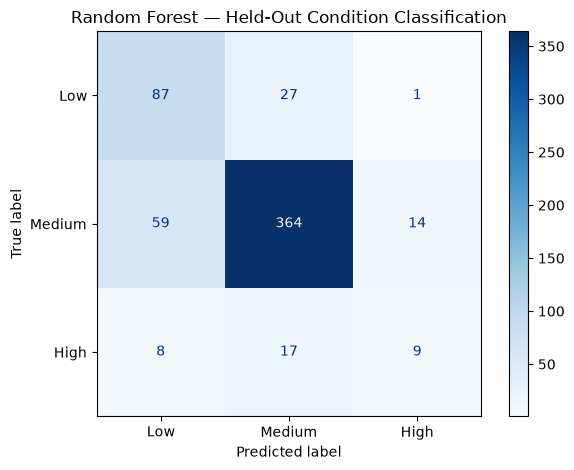

In [28]:
# References
# https://scikit-learn.org/stable/modules/generated/sklearn.base.clone.html
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Refitting the selected pipeline on all training properties.
final_condition_model = clone(forest_condition_model)
final_condition_model.fit(X_condition_train, y_condition_train)

# Predicting condition categories for the held-out properties.
condition_test_predictions = final_condition_model.predict(X_condition_test)
condition_labels = ["Low", "Medium", "High"]

# Reporting precision, recall, F1, and the number of test properties per class.
report = classification_report(
    y_condition_test,
    condition_test_predictions,
    labels=condition_labels,
    output_dict=True,
    zero_division=0,
)

report_table = pd.DataFrame.from_dict(
    {label: report[label] for label in condition_labels + ["macro avg"]},
    orient="index",
).rename(columns={"support": "Test properties"})

report_table["Test properties"] = report_table["Test properties"].astype(int)

print(f"Test properties: {len(y_condition_test)}")
print(f"Test accuracy: {report['accuracy']:.2%}")
print(f"Test macro F1: {report['macro avg']['f1-score']:.4f}")
print(f"Test high-risk recall: {report['High']['recall']:.2%}")
display(report_table.round(4))

# Rows are actual categories and columns are predicted categories.
ConfusionMatrixDisplay.from_predictions(
    y_condition_test,
    condition_test_predictions,
    labels=condition_labels,
    cmap="Blues",
    values_format="d",
)
plt.title("Random Forest — Held-Out Condition Classification")
plt.tight_layout()
plt.show()

Interpretation: Random Forest was selected because it achieved the highest mean validation macro F1 (0.6334) among the three classifiers. 
On the held-out test set, it correctly classified 460 of 586 properties (78.50%) and achieved a macro F1 of 0.6062. 
Recall was highest for the Medium category (83.30%) and lowest for the High category (26.47%). The model 
missed 25 of the 34 properties labeled High, which limits its usefulness for flagging properties in that category. 
These categories were derived from the Ames Overall Cond ratings and represent a proxy for condition risk.

# Feature Importance

### Sale Price Predictors in the XGBoost Model. 
We use permutation imortance to measure how much the fitted XGBoost model relies on each feature. 

,Feature,Mean MAE Increase ($),Standard Deviation ($)
16,Overall Qual,14923.02,875.85
45,Gr Liv Area,10070.38,530.42
37,Total Bsmt SF,3067.15,292.85
18,Year Built,2114.26,201.85
33,BsmtFin SF 1,1753.56,163.12
19,Year Remod/Add,1521.97,123.57
3,Lot Area,1372.87,152.13
17,Overall Cond,1180.45,151.40
60,Garage Cars,973.38,78.15
55,Fireplaces,785.17,125.85


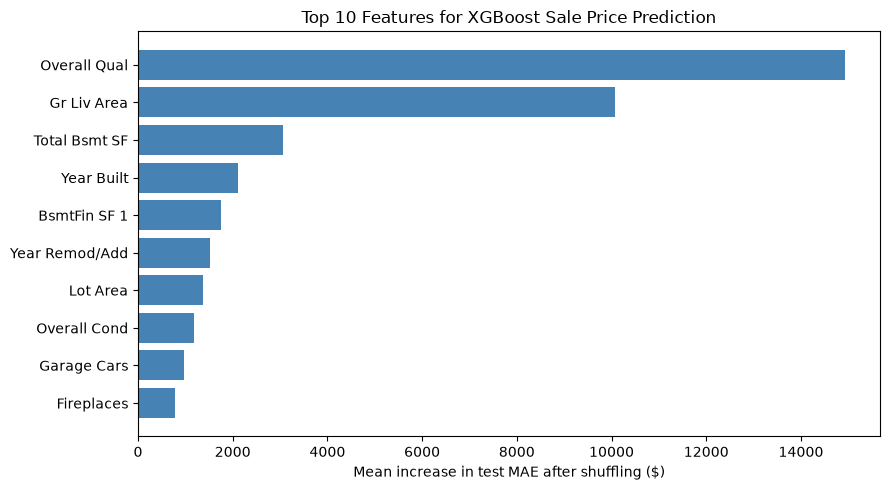

In [30]:
# References
# scikit-learn permutation importance:
# https://scikit-learn.org/stable/modules/permutation_importance.html
# https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html

import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Shuffling each original feature 10 times and measure the change in test MAE.
price_permutation = permutation_importance(
    final_price_model,
    X_price_test,
    y_price_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
)

# With this scorer, positive importance means shuffling increased MAE.
price_importance = pd.DataFrame({
    "Feature": X_price_test.columns,
    "Mean MAE Increase ($)": price_permutation.importances_mean,
    "Standard Deviation ($)": price_permutation.importances_std,
}).sort_values("Mean MAE Increase ($)", ascending=False)

top_price_features = price_importance.head(10)
display(top_price_features.round(2))

# Reversing the display order so the strongest feature appears at the top.
plot_features = top_price_features.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    plot_features["Feature"],
    plot_features["Mean MAE Increase ($)"],
    color="steelblue",
)
ax.set_title("Top 10 Features for XGBoost Sale Price Prediction")
ax.set_xlabel("Mean increase in test MAE after shuffling ($)")
fig.tight_layout()
plt.show()

Interpretation:
Overall quality (Overall Qual) and above-ground living area (Gr Liv Area) were the two features the XGBoost sale-price model relied on most. Shuffling these features increased the mean absolute error on the test set by $14,923.02 and $10,070.38, respectively. Total basement area (Total Bsmt SF) ranked third, with an increase of $3,067.15.
The recorded overall condition rating (Overall Cond) ranked eighth. Shuffling it increased mean absolute error by $1,180.45. Each dollar amount measures how much the model’s prediction error increased, on average, when that feature’s values were shuffled across the test properties.

### Property Condition Predictors in the Random Forest Model

,Feature,Mean Macro F1 Decrease,Standard Deviation
18,Year Remod/Add,0.0708,0.0151
16,Overall Qual,0.0381,0.0122
51,Kitchen Qual,0.0362,0.0118
17,Year Built,0.0255,0.0101
26,Exter Cond,0.0227,0.0061
29,Bsmt Cond,0.0192,0.0012
39,Central Air,0.0159,0.0028
40,Electrical,0.0147,0.0014
25,Exter Qual,0.0112,0.0123
42,2nd Flr SF,0.0099,0.0030


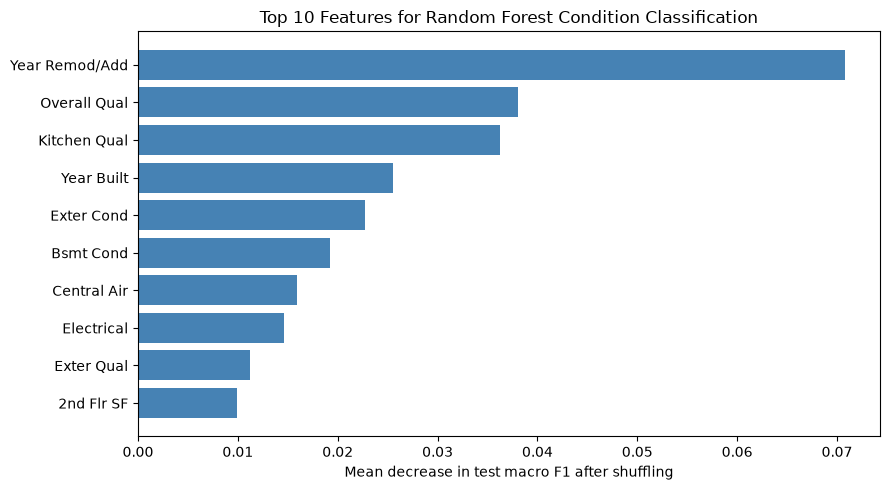

In [31]:
# References
# https://scikit-learn.org/stable/modules/permutation_importance.html
# https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html

# Shuffling each feature 10 times on the held-out properties.
condition_permutation = permutation_importance(
    final_condition_model,
    X_condition_test,
    y_condition_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
)

# Ranking the original columns by the average drop in macro F1.
condition_importance = pd.DataFrame({
    "Feature": X_condition_test.columns,
    "Mean Macro F1 Decrease": condition_permutation.importances_mean,
    "Standard Deviation": condition_permutation.importances_std,
}).sort_values("Mean Macro F1 Decrease", ascending=False)

top_condition_features = condition_importance.head(10)
display(top_condition_features.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    top_condition_features["Feature"],
    top_condition_features["Mean Macro F1 Decrease"],
    color="steelblue",
)
ax.invert_yaxis()
ax.set_title("Top 10 Features for Random Forest Condition Classification")
ax.set_xlabel("Mean decrease in test macro F1 after shuffling")
fig.tight_layout()
plt.show()

Interpretation:
Remodel year was the feature the Random Forest condition classifier relied on most. Shuffling it reduced 
test macro F1 by 0.0708 on average. Overall quality and kitchen quality followed, with average decreases of
0.0381 and 0.0362, respectively. Exterior condition and basement condition also appeared in the top ten. 
These rankings describe performance across all three condition categories. The model identified only 9 of 34 
properties in the High category, so the overall ranking gives limited insight into which features help detect 
those properties specifically.
    

### Comparing the Most Influential Features Across Both Models

In [ ]:
Overall quality, year built, and remodel year appeared in the top ten for both models. Overall quality and above-ground 
living area led the XGBoost sale-price rankings, while remodel year led the Random Forest condition rankings. The price 
rankings measure increases in prediction error in dollars. The condition rankings measure decreases in macro F1. Comparing
the ranks shows which features stood out for each task.

# Model Interpretation with SHAP

Property row index: 1320
Actual sale price: $325,000.00
Model baseline: $182,130.03
Baseline plus all contributions: $325,413.15
Predicted sale price: $325,413.12


,Feature,Contribution ($)
2,numeric__Overall Qual,94868.28
14,numeric__Gr Liv Area,46380.41
102,categorical__Condition 2_PosA,17244.37
4,numeric__Year Built,-11430.19
27,numeric__Open Porch SF,-7721.18
17,numeric__Full Bath,7425.15
5,numeric__Year Remod/Add,6151.67
3,numeric__Overall Cond,4683.65
7,numeric__BsmtFin SF 1,-4197.24
10,numeric__Total Bsmt SF,-4118.10


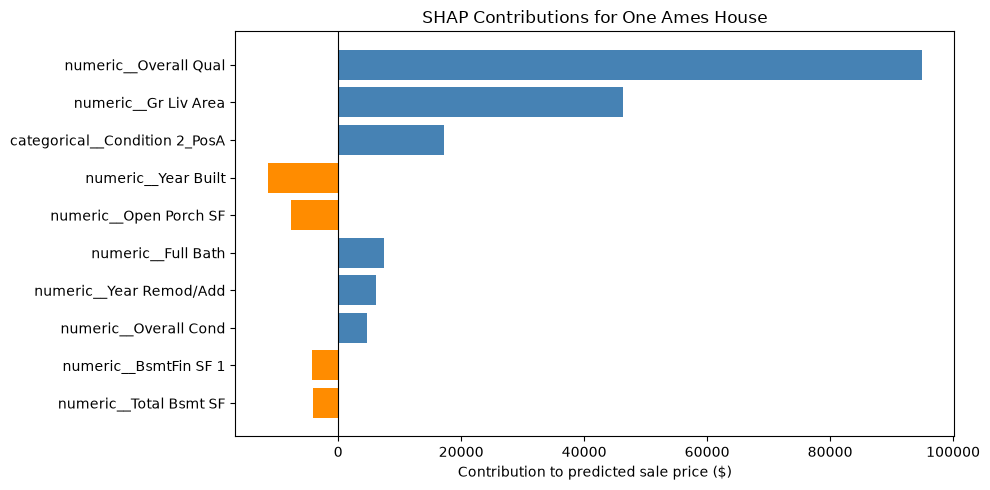

In [33]:
# References
# https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.predict

from xgboost import DMatrix

# Applying the fitted preprocessing to the first test house.
house = X_price_test.iloc[[0]]
preprocessor = final_price_model.named_steps["preprocessing"]
regressor = final_price_model.named_steps["regression"]
house_encoded = preprocessor.transform(house)

# XGBoost returns one SHAP value per encoded feature, then the baseline.
contributions = regressor.get_booster().predict(
    DMatrix(house_encoded, missing=regressor.missing),
    pred_contribs=True,
)[0]

baseline = float(contributions[-1])
feature_effects = contributions[:-1].astype(float)
predicted_price = float(final_price_model.predict(house)[0])

shap_table = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Contribution ($)": feature_effects,
})

# Showing the ten largest contributions in either direction.
top_shap = shap_table.sort_values(
    "Contribution ($)", key=lambda values: values.abs(), ascending=False
).head(10)

print(f"Property row index: {house.index[0]}")
print(f"Actual sale price: ${y_price_test.iloc[0]:,.2f}")
print(f"Model baseline: ${baseline:,.2f}")
print(f"Baseline plus all contributions: ${baseline + feature_effects.sum():,.2f}")
print(f"Predicted sale price: ${predicted_price:,.2f}")
display(top_shap.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(
    top_shap["Feature"],
    top_shap["Contribution ($)"],
    color=["steelblue" if value >= 0 else "darkorange"
           for value in top_shap["Contribution ($)"]],
)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("SHAP Contributions for One Ames House")
ax.set_xlabel("Contribution to predicted sale price ($)")
fig.tight_layout()
plt.show()

In [ ]:
Interpretation:
For property 1320, the XGBoost model started from a baseline of $182,130.03 and predicted a sale price of $325,413.12. 
Overall quality and above-ground living area made the largest positive contributions, raising the estimate by $94,868.28 and
$46,380.41, respectively. Year built and open porch area made the largest negative contributions, lowering the estimate by
$11,430.19 and $7,721.18, respectively. Overall condition contributed $4,683.65 to the estimate. These amounts describe how 
the model arrived at its prediction for this particular house.

# Streamlit Dashboard

### Saving the Trained Models

In [34]:
# References
# https://scikit-learn.org/stable/model_persistence.html
# https://joblib.readthedocs.io/en/latest/generated/joblib.dump.html
# https://joblib.readthedocs.io/en/latest/generated/joblib.load.html

from pathlib import Path

import joblib
from numpy.testing import assert_allclose

models_folder = Path("models")
models_folder.mkdir(exist_ok=True)

price_model_path = models_folder / "xgboost_price_model.joblib"
condition_model_path = models_folder / "random_forest_condition_model.joblib"

# Saveing each fitted pipeline, including its preprocessing.
joblib.dump(final_price_model, price_model_path)
joblib.dump(final_condition_model, condition_model_path)

# Reloading the files and check predictions using one test property.
saved_price_model = joblib.load(price_model_path)
saved_condition_model = joblib.load(condition_model_path)

sample_price_input = X_price_test.iloc[[0]]
sample_condition_input = X_condition_test.iloc[[0]]

original_price = final_price_model.predict(sample_price_input)
reloaded_price = saved_price_model.predict(sample_price_input)
assert_allclose(reloaded_price, original_price)

original_condition = final_condition_model.predict(sample_condition_input)[0]
reloaded_condition = saved_condition_model.predict(sample_condition_input)[0]
assert reloaded_condition == original_condition

print("Models saved in:", models_folder.resolve())
print(f"Verified price prediction: ${reloaded_price[0]:,.2f}")
print(f"Verified condition prediction: {reloaded_condition}")

Models saved in: C:\Users\nyamb\models
Verified price prediction: $325,413.12
Verified condition prediction: Low


### Preparing Inputs for the Property Form
The two models were trained with different columns and so the form needs to know which inputs to send to each model. 


In [35]:
# References
# https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
# https://joblib.readthedocs.io/en/latest/generated/joblib.dump.html

# Storing the feature order each fitted pipeline expects.
price_columns = final_price_model.feature_names_in_.tolist()
condition_columns = final_condition_model.feature_names_in_.tolist()

# Keeping the verified example so we can reproduce both predictions in the app.
dashboard_inputs = {
    "price_columns": price_columns,
    "condition_columns": condition_columns,
    "example_property": sample_price_input.copy(),
}

dashboard_inputs_path = models_folder / "dashboard_inputs.joblib"
joblib.dump(dashboard_inputs, dashboard_inputs_path)

print("Dashboard inputs saved to:", dashboard_inputs_path.resolve())
print("Sale price inputs:", len(price_columns))
print("Condition inputs:", len(condition_columns))

Dashboard inputs saved to: C:\Users\nyamb\models\dashboard_inputs.joblib
Sale price inputs: 75
Condition inputs: 74


### Building the Property Input Form

In [36]:
%%writefile "C:/Users/nyamb/app.py"

# References
# https://docs.streamlit.io/develop/api-reference/data/st.data_editor
# https://docs.streamlit.io/develop/api-reference/execution-flow/st.form
# https://joblib.readthedocs.io/en/latest/generated/joblib.load.html

from pathlib import Path

import joblib
import streamlit as st

st.set_page_config(page_title="Smart Property Analytics", layout="wide")
st.title("Smart Property Analytics")

# Finding the files relative to app.py so the launch folder can vary.
models_folder = Path(__file__).resolve().parent / "models"
price_path = models_folder / "xgboost_price_model.joblib"
condition_path = models_folder / "random_forest_condition_model.joblib"
inputs_path = models_folder / "dashboard_inputs.joblib"

missing_files = [
    path.name for path in (price_path, condition_path, inputs_path)
    if not path.is_file()
]
if missing_files:
    st.error(f"Missing files in {models_folder}: {', '.join(missing_files)}")
    st.stop()

price_model = joblib.load(price_path)
condition_model = joblib.load(condition_path)
inputs = joblib.load(inputs_path)

st.write("Edit the example property below. Scroll right to see all fields.")
st.caption("Overall Cond is used for the sale price estimate only.")

with st.form("property_input"):
    property_data = st.data_editor(
        inputs["example_property"],
        hide_index=True,
        num_rows="fixed",
    )
    submitted = st.form_submit_button("Predict")

if submitted:
    # Sending each pipeline its own columns in the order used during training.
    price_input = property_data[inputs["price_columns"]]
    condition_input = property_data[inputs["condition_columns"]]

    price = price_model.predict(price_input)[0]
    condition = condition_model.predict(condition_input)[0]

    price_panel, condition_panel = st.columns(2)
    price_panel.metric("Estimated sale price", f"${price:,.2f}")
    condition_panel.metric("Predicted condition category", str(condition))
    st.caption("The condition category is derived from Ames assessor ratings.")

Writing C:/Users/nyamb/app.py


### Displaying Sale Price Estimates and Condition Predictions

On Anaconda Prompt, run the following lines to launch the dashboard with the same environment used to 
train the models.  

conda activate nyamb_env

python -m streamlit run "C:\Users\nyamb\app.py"

When the user clicks Predict, the dashboard sends the property details to both models. XGBoost displays the estimated 
sale price in dollars, and Random Forest displays the predicted condition category: Low, Medium, or High.

### Testing the Dashboard with Sample Properties
I used three inputs to check that the dashboard could display a sale price estimate and a condition category.
The first test used the prefilled property to check that the dashboard reproduced the notebook results. 
The other two tests used edited inputs to check that the form accepted changes and returned both predictions.

In [38]:
# References
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html
# https://pandas.pydata.org/docs/user_guide/style.html
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.insert.html
# https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html

import pandas as pd
from IPython.display import display

sample_inputs = pd.DataFrame(
    [
        ("Property details", "Overall Qual", 6, 8),
        ("Property details", "Overall Cond", 5, 7),
        ("Property details", "Year Built", 1975, 2004),
        ("Property details", "Year Remod/Add", 2000, 2008),
        ("Living area and bathrooms", "1st Flr SF", 1250, 1500),
        ("Living area and bathrooms", "2nd Flr SF", 0, 650),
        ("Living area and bathrooms", "Low Qual Fin SF", 0, 0),
        ("Living area and bathrooms", "Gr Liv Area", 1250, 2150),
        ("Living area and bathrooms", "Full Bath", 1, 2),
        ("Basement and garage", "BsmtFin SF 1", 450, 850),
        ("Basement and garage", "BsmtFin SF 2", 0, 0),
        ("Basement and garage", "Bsmt Unf SF", 550, 350),
        ("Basement and garage", "Total Bsmt SF", 1000, 1200),
        ("Basement and garage", "Garage Cars", 1, 2),
        ("Basement and garage", "Garage Area", 280, 520),
    ],
    columns=["Property details", "Form field", "House A", "House B"],
).set_index(["Property details", "Form field"])

# The dashboard starts with the first property in the held-out test set.
# List its saved values in the same field order as the sample inputs table.

form_fields = sample_inputs.index.get_level_values("Form field")
prefilled_property = dashboard_inputs["example_property"].iloc[0]
prefilled_values = prefilled_property.reindex(form_fields)

sample_inputs.insert(0, "Prefilled property", prefilled_values.to_numpy())


# Styling the display while keeping the sample values as integers.
display(
    sample_inputs.style
    .set_caption("Sample inputs for dashboard testing")
    .format("{:.0f}", na_rep="Blank")
    .set_properties(**{"padding": "6px 16px", "text-align": "right"})
    .set_table_styles([
        {
            "selector": "caption",
            "props": [("font-weight", "bold"), ("text-align", "left")],
        },
        {
            "selector": "thead th",
            "props": [("background-color", "#24527a"), ("color", "white")],
        },
        {
            "selector": "tbody tr:nth-child(even) td",
            "props": [("background-color", "#eef4f8"), ("color", "#172b3a")],
        },
    ])
)

## Prefilled Property Results
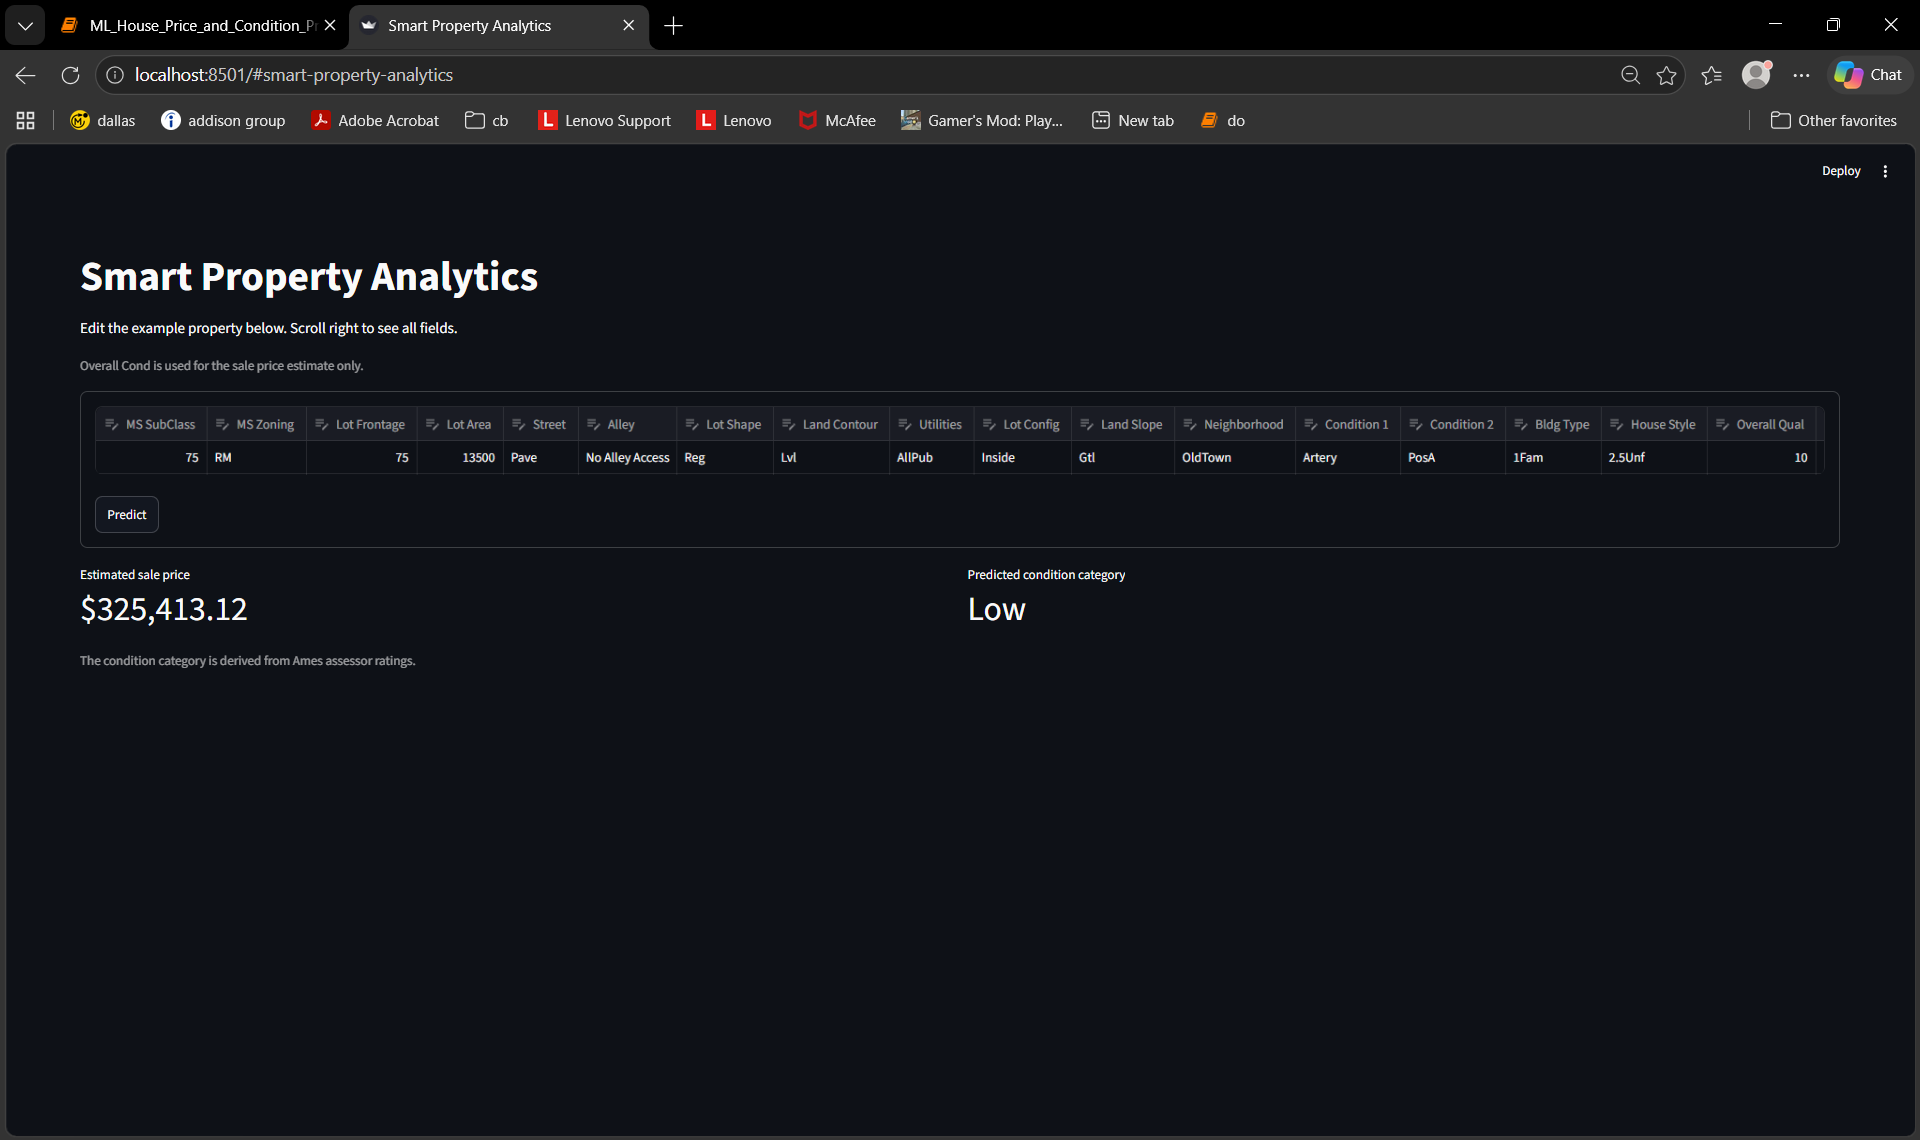

## House A Results
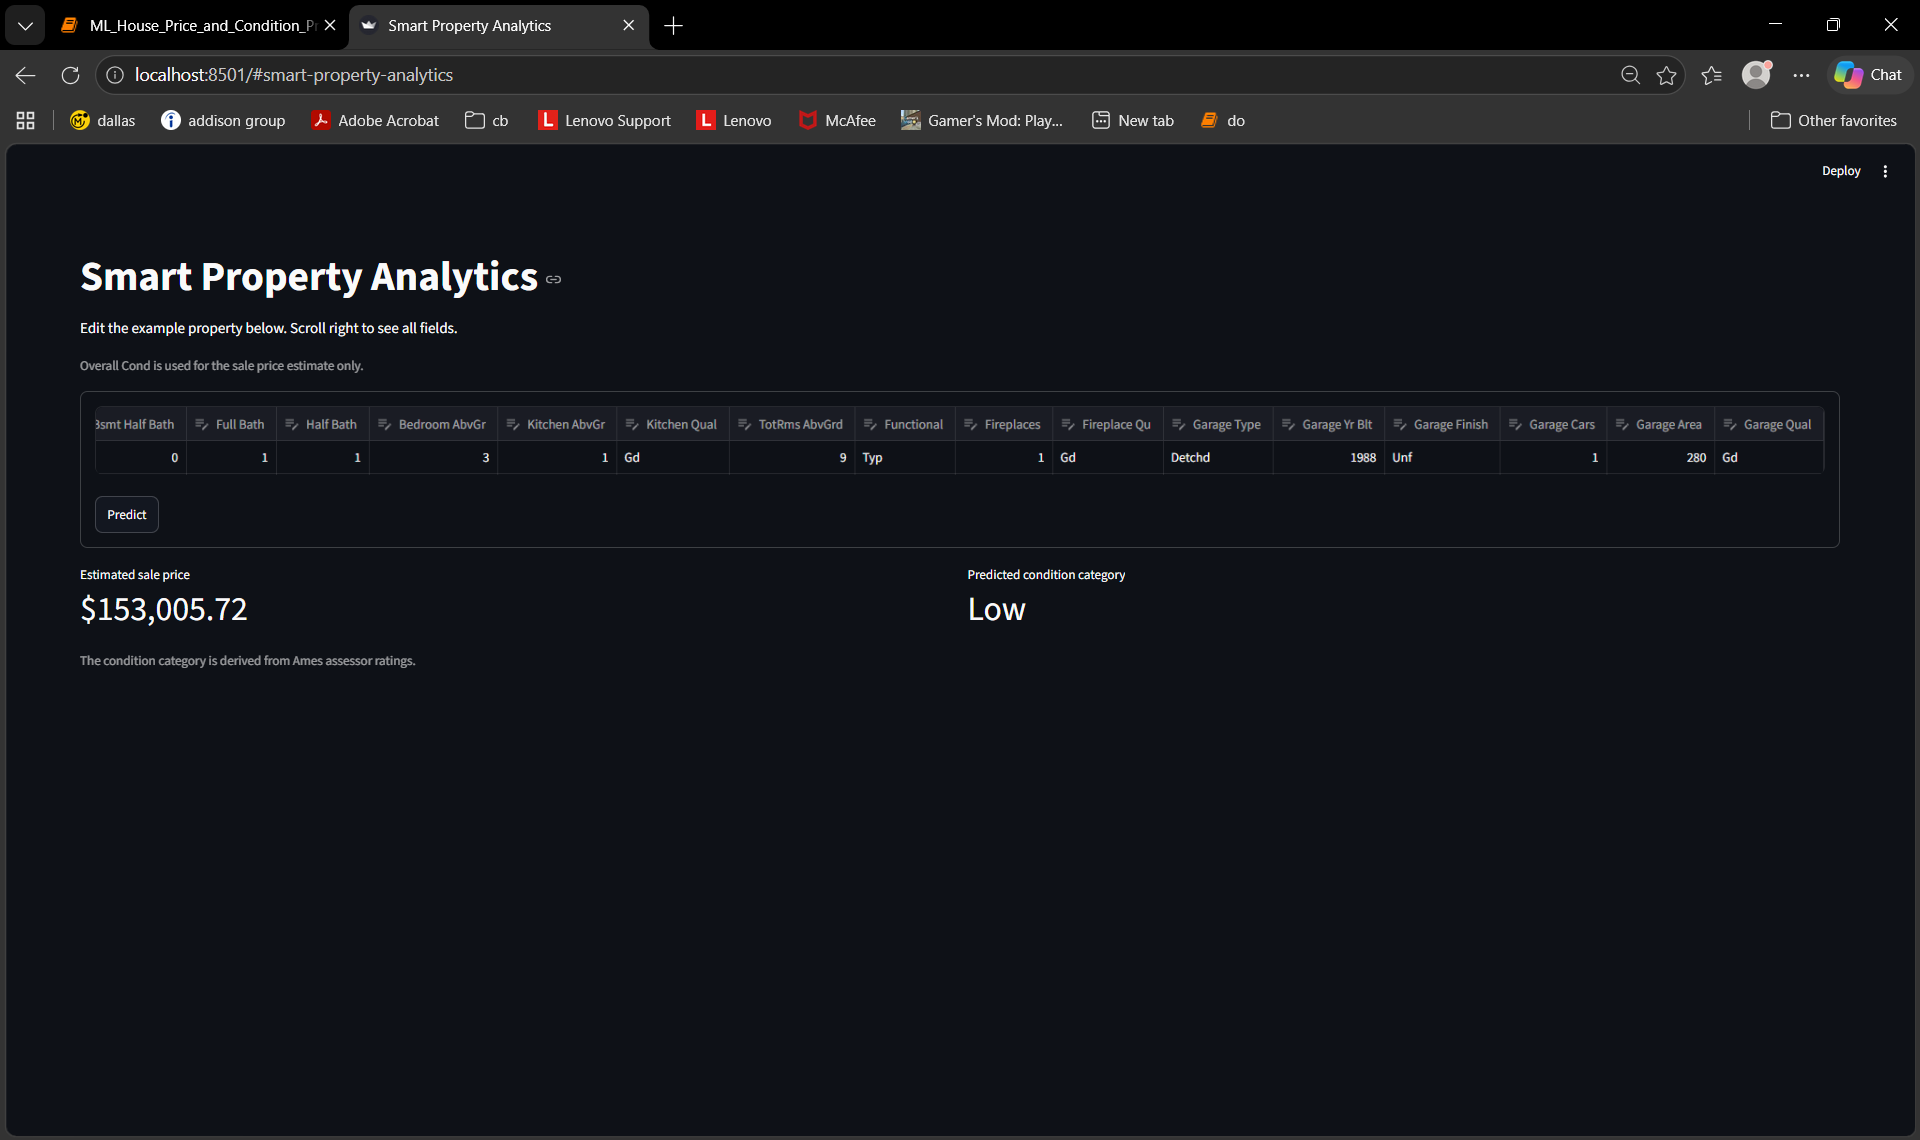

## House B Results
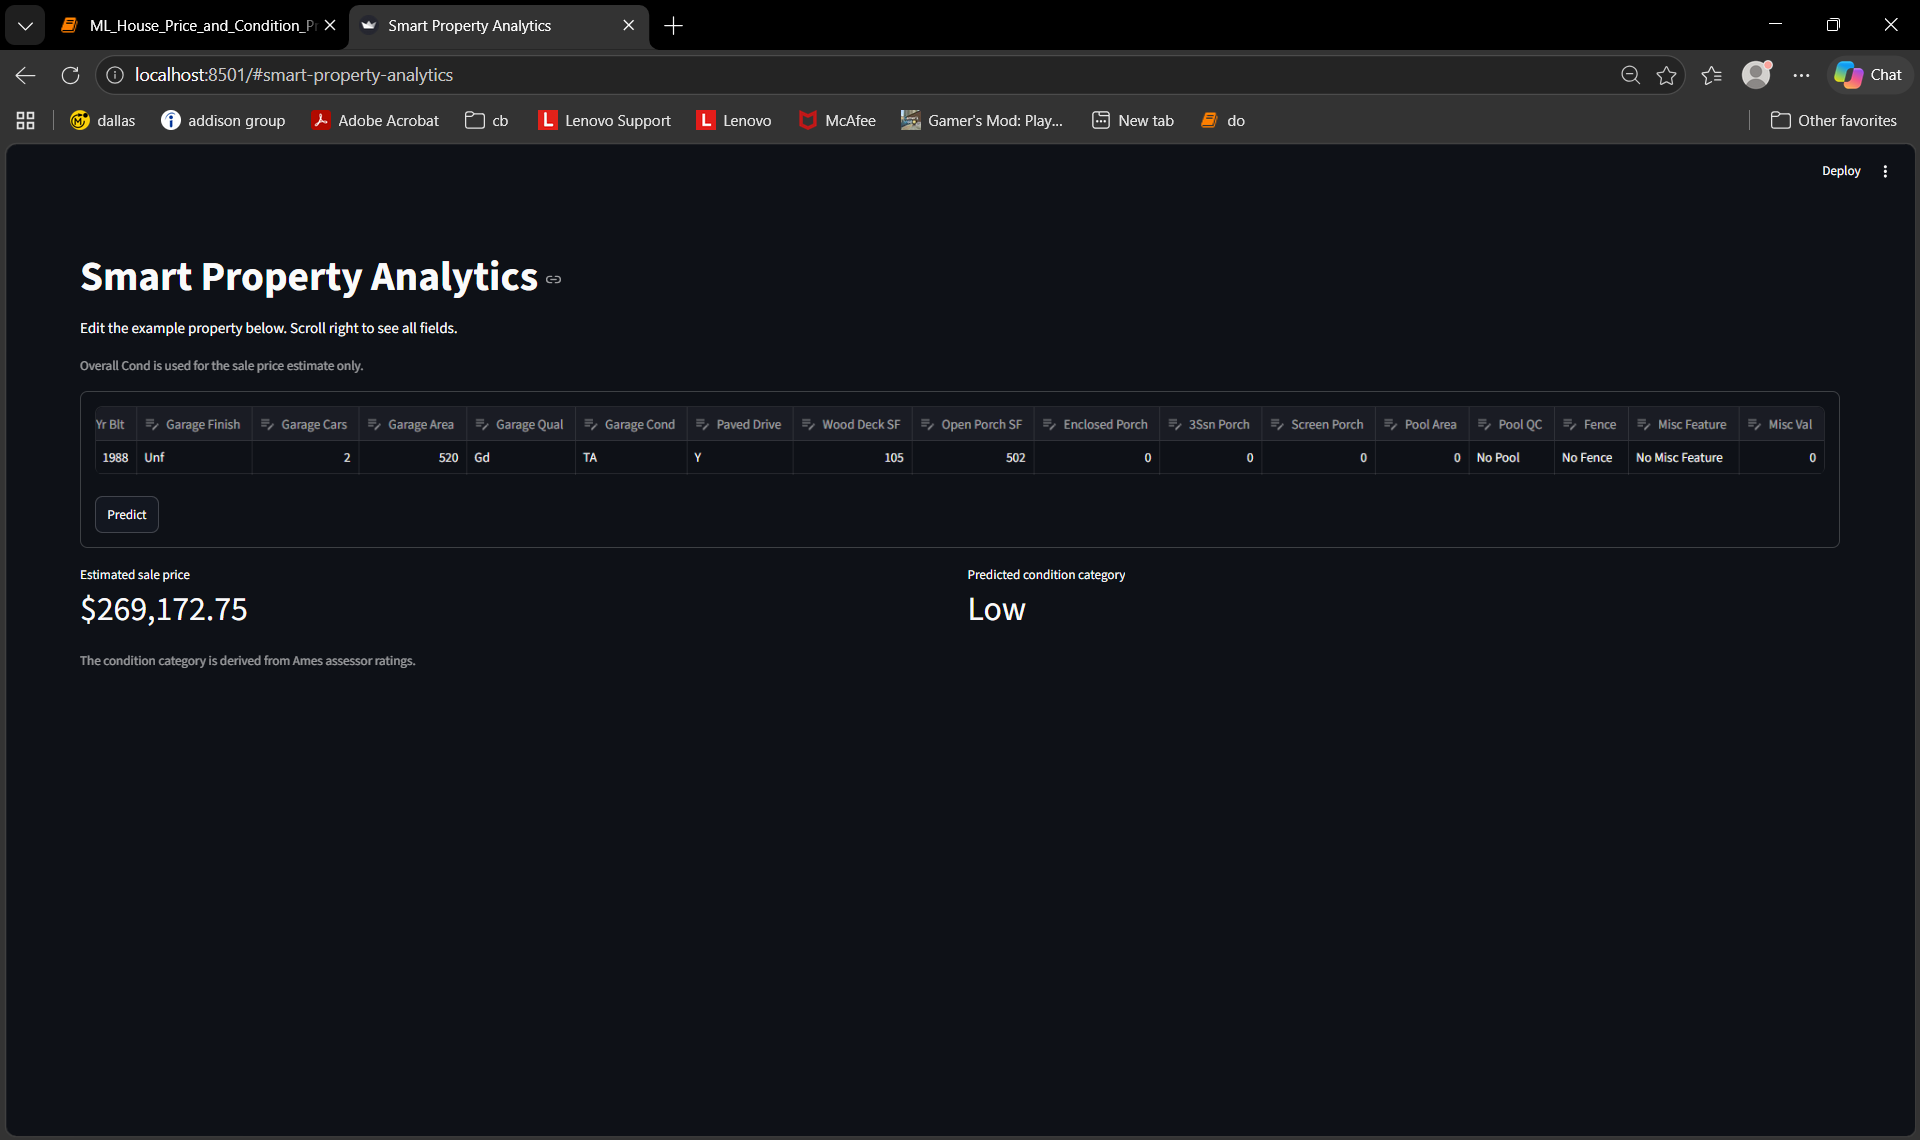

### Exporting Model Evaluation Results

In [41]:
# References
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

from sklearn.metrics import confusion_matrix

# Saving the held-out metrics beside the fitted models.
price_test_results.to_csv(models_folder / "price_test_results.csv", index=False)
report_table.to_csv(models_folder / "condition_test_results.csv")

# Keeping the category order consistent with the notebook's confusion matrix.
condition_labels = ["Low", "Medium", "High"]
condition_confusion = pd.DataFrame(
    confusion_matrix(
        y_condition_test,
        condition_test_predictions,
        labels=condition_labels,
    ),
    index=pd.Index(condition_labels, name="Actual"),
    columns=condition_labels,
)
condition_confusion.to_csv(models_folder / "condition_confusion_matrix.csv")

print("Evaluation files saved in:", models_folder.resolve())
display(condition_confusion)

Evaluation files saved in: C:\Users\nyamb\models


,Low,Medium,High
Actual,,,
Low,87,27,1
Medium,59,364,14
High,8,17,9


### Adding the Model Evaluation Tab

In [42]:
%%writefile "C:/Users/nyamb/app.py"
# References
# https://docs.streamlit.io/develop/api-reference/layout/st.tabs
# https://docs.streamlit.io/develop/api-reference/data/st.data_editor
# https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Smart Property Analytics", layout="wide")
st.title("Smart Property Analytics")

# Using the models folder beside app.py.
models_folder = Path(__file__).resolve().parent / "models"
prediction_tab, evaluation_tab = st.tabs(["Predict", "Model Evaluation"])

with prediction_tab:
    model_files = [
        "xgboost_price_model.joblib",
        "random_forest_condition_model.joblib",
        "dashboard_inputs.joblib",
    ]
    missing_models = [
        name for name in model_files if not (models_folder / name).is_file()
    ]

    if missing_models:
        st.error("Missing prediction files: " + ", ".join(missing_models))
    else:
        price_model = joblib.load(models_folder / model_files[0])
        condition_model = joblib.load(models_folder / model_files[1])
        inputs = joblib.load(models_folder / model_files[2])

        st.write("Edit the example property. Scroll right to see all fields.")
        st.caption("Overall Cond is used for the sale price estimate only.")

        with st.form("property_input"):
            property_data = st.data_editor(
                inputs["example_property"], hide_index=True, num_rows="fixed"
            )
            submitted = st.form_submit_button("Predict")

        if submitted:
            # Sending each pipeline its own feature columns in training order.
            price = price_model.predict(property_data[inputs["price_columns"]])[0]
            condition = condition_model.predict(
                property_data[inputs["condition_columns"]]
            )[0]

            price_panel, condition_panel = st.columns(2)
            price_panel.metric("Estimated sale price", f"${price:,.2f}")
            condition_panel.metric("Predicted condition category", str(condition))
            st.caption("The condition categories are derived from Ames assessor ratings.")

with evaluation_tab:
    evaluation_files = [
        "price_test_results.csv",
        "condition_test_results.csv",
        "condition_confusion_matrix.csv",
    ]
    missing_results = [
        name for name in evaluation_files if not (models_folder / name).is_file()
    ]

    if missing_results:
        st.info(
            "Run the Exporting Model Evaluation Results cell in Jupyter. "
            "Missing files: " + ", ".join(missing_results)
        )
    else:
        # Loading the notebook's held-out results without retraining.
        price_results = pd.read_csv(models_folder / evaluation_files[0])
        condition_results = pd.read_csv(
            models_folder / evaluation_files[1], index_col=0
        )
        confusion = pd.read_csv(
            models_folder / evaluation_files[2], index_col=0
        )

        st.subheader("Sale Price Prediction")
        st.dataframe(price_results.round(4), hide_index=True)

        st.subheader("Property Condition Classification")
        st.dataframe(condition_results.round(4))

        st.subheader("Confusion Matrix")
        st.caption("Rows show actual categories. Columns show predicted categories.")
        st.dataframe(confusion)

        high_correct = int(confusion.loc["High", "High"])
        high_total = int(confusion.loc["High"].sum())
        st.write(
            f"The model correctly flagged {high_correct} of the "
            f"{high_total} properties in the High category."
        )

Overwriting C:/Users/nyamb/app.py


## Model Evaluation Results:
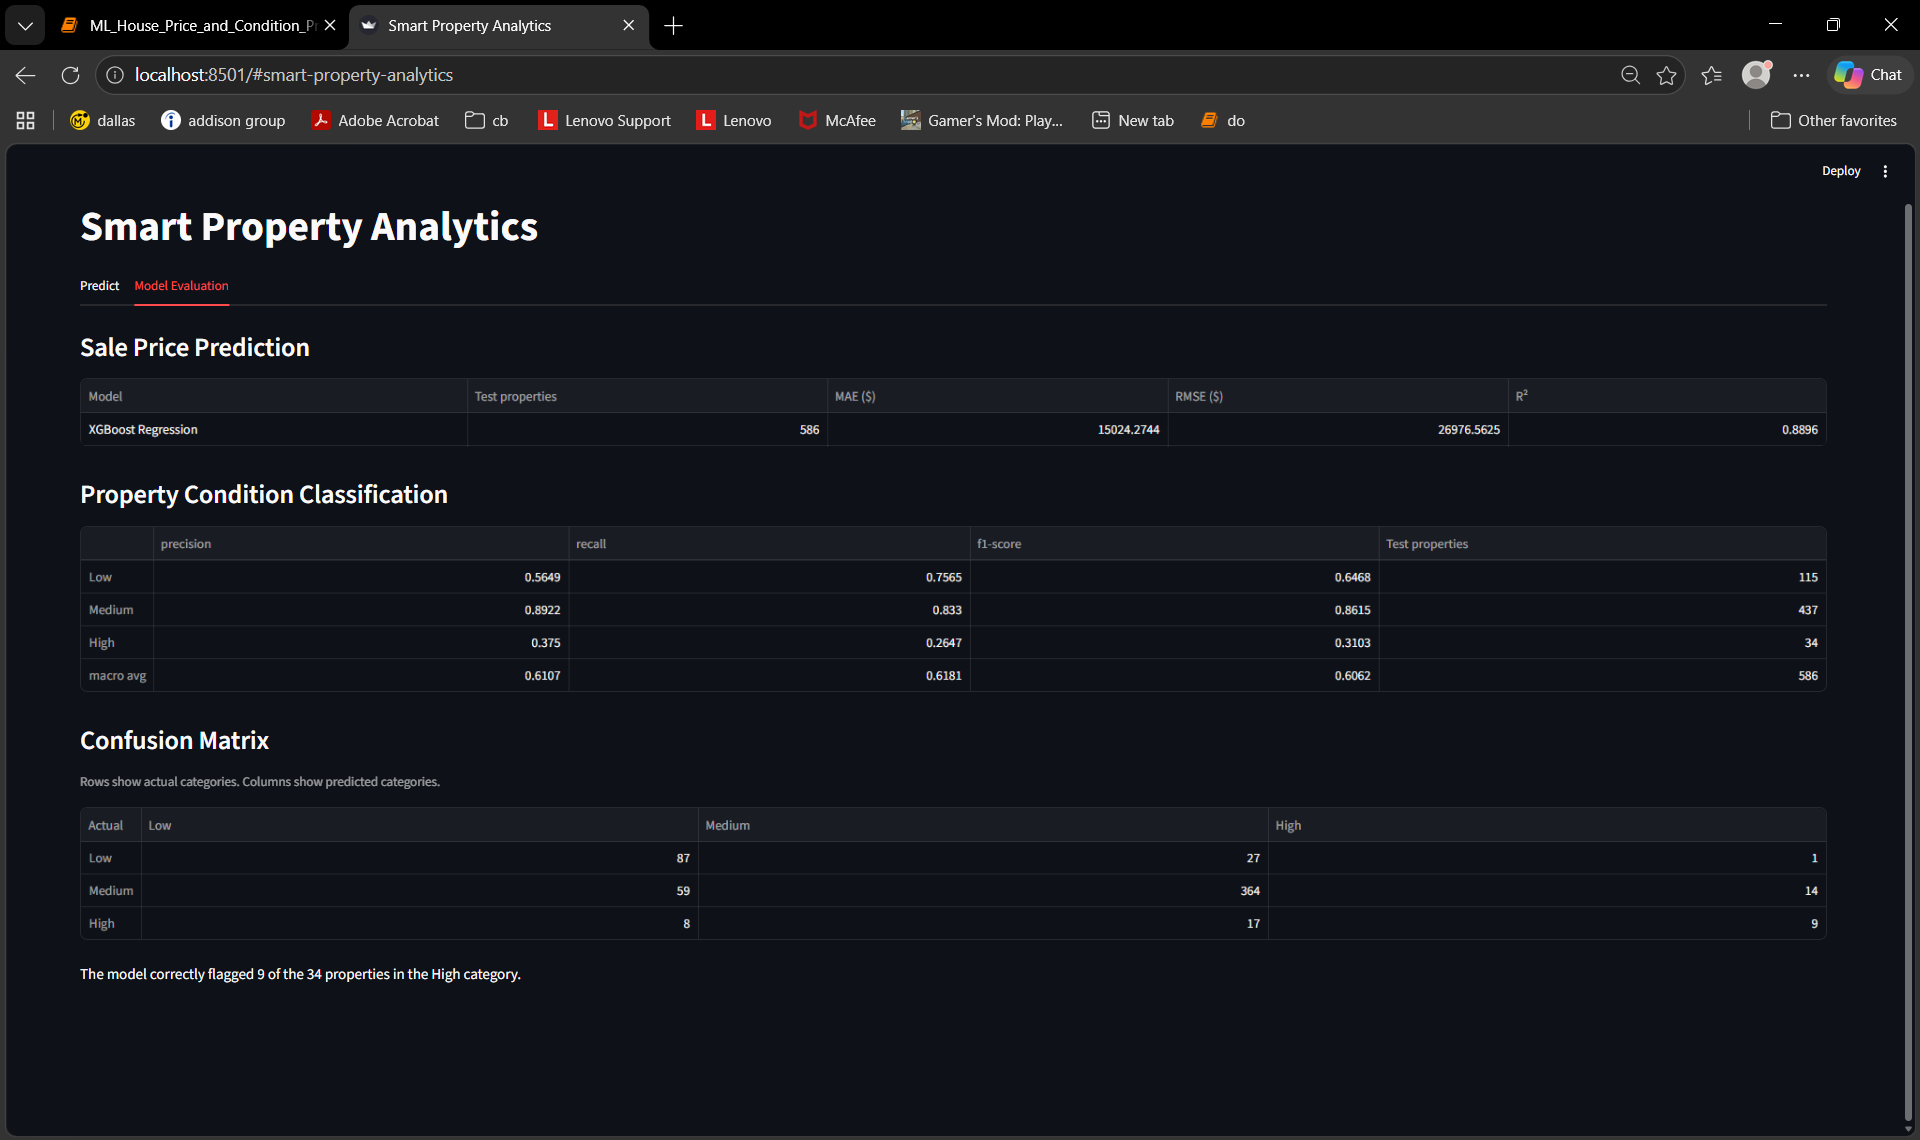

Explanation:

We can verify both tabs whereby predict reproduces $325,413.12 and Low with the prefilled property. 
We check how well the models performed on 586 held-out properties and whether the updated dashboard correctly displays teh evaluation and reproduces the prefilled prediction. 

Sale price: XGBoost’s MAE was $15,024.27, so its estimates differed from actual sale prices by about $15,024 on average, regardless of direction. Its RMSE was higher at $26,976.56 because RMSE gives larger errors more weight. The prefilled property was off by only $413.12, a close result for that particular house.

Property condition: Random Forest got 460 of 586 categories right (78.50% accuracy), but it identified only 9 of 34 properties in the High category (26.47% recall). It classified the other 25 as Medium or Low. The Medium group made up 437 of 586 test properties, so overall accuracy gives more weight to performance on that group. Macro F1 (0.6062) gives each category equal weight.

### Exporting Data for Exploratory Analysis

In [44]:
# References
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html

# Comparing missing values before and after the notebook's cleaning steps.
missing_summary = pd.DataFrame({
    "Before cleaning": housingData.isna().sum(),
    "After cleaning": housingClean.isna().sum(),
})
missing_summary = missing_summary.loc[
    missing_summary["Before cleaning"] > 0
].sort_values("Before cleaning", ascending=False)

missing_summary.to_csv(models_folder / "missing_values_summary.csv", index_label="Feature")

# Exporting the columns needed for the dashboard's exploratory charts.
eda_columns = ["SalePrice", "Gr Liv Area", "Overall Qual", "Neighborhood"]
eda_data = housingClean[eda_columns]
eda_data.to_csv(models_folder / "housing_eda.csv", index=False)

print("Exploratory analysis files saved in:", models_folder.resolve())
print("Properties exported:", len(eda_data))
display(missing_summary.head(10))

Exploratory analysis files saved in: C:\Users\nyamb\models
Properties exported: 2930


,Before cleaning,After cleaning
Pool QC,2917,0
Misc Feature,2824,0
Alley,2732,0
Fence,2358,0
Mas Vnr Type,1775,30
Fireplace Qu,1422,0
Lot Frontage,490,490
Garage Qual,159,2
Garage Cond,159,2
Garage Yr Blt,159,159


### Adding the Data and Exploratory Analysis Tab

In [45]:
# References
# https://docs.python.org/3/library/pathlib.html
# https://docs.streamlit.io/develop/api-reference/layout/st.tabs
# https://docs.streamlit.io/develop/api-reference/charts/st.scatter_chart

from pathlib import Path

app_path = Path(r"C:\Users\nyamb\app.py")
app_code = app_path.read_text(encoding="utf-8")

old_tabs = 'prediction_tab, evaluation_tab = st.tabs(["Predict", "Model Evaluation"])'
new_tabs = '''prediction_tab, evaluation_tab, eda_tab = st.tabs(
    ["Predict", "Model Evaluation", "Data and Exploratory Analysis"]
)'''

eda_section = '''
with eda_tab:
    missing_path = models_folder / "missing_values_summary.csv"
    eda_path = models_folder / "housing_eda.csv"

    if missing_path.is_file() and eda_path.is_file():
        missing_summary = pd.read_csv(missing_path)
        eda_data = pd.read_csv(eda_path)

        st.subheader("Missing Values Before and After Cleaning")
        st.caption("Counts reflect the notebook cleaning steps before model imputation.")
        st.dataframe(missing_summary, hide_index=True)

        st.subheader("Above-Ground Living Area and Sale Price")
        st.caption(f"Each point represents one of {len(eda_data):,} Ames properties.")
        chart_data = eda_data.rename(columns={
            "Gr Liv Area": "Above-ground living area (sq ft)",
            "SalePrice": "Sale price ($)",
        })
        st.scatter_chart(
            chart_data,
            x="Above-ground living area (sq ft)",
            y="Sale price ($)",
        )
    else:
        st.info("Run the exploratory data export cell in Jupyter first.")
'''

# Adding the tab once, using the layout from the previous notebook cell.
if "with eda_tab:" in app_code:
    print("The exploratory analysis tab is already in app.py.")
elif app_code.count(old_tabs) != 1:
    raise ValueError("Could not find the existing two-tab layout in app.py.")
else:
    updated_code = app_code.replace(old_tabs, new_tabs, 1)
    updated_code = updated_code.rstrip() + "\n\n" + eda_section.lstrip()
    compile(updated_code, str(app_path), "exec")
    app_path.write_text(updated_code, encoding="utf-8")
    print("Updated:", app_path)

Updated: C:\Users\nyamb\app.py


Exploratory data analysis tab results:
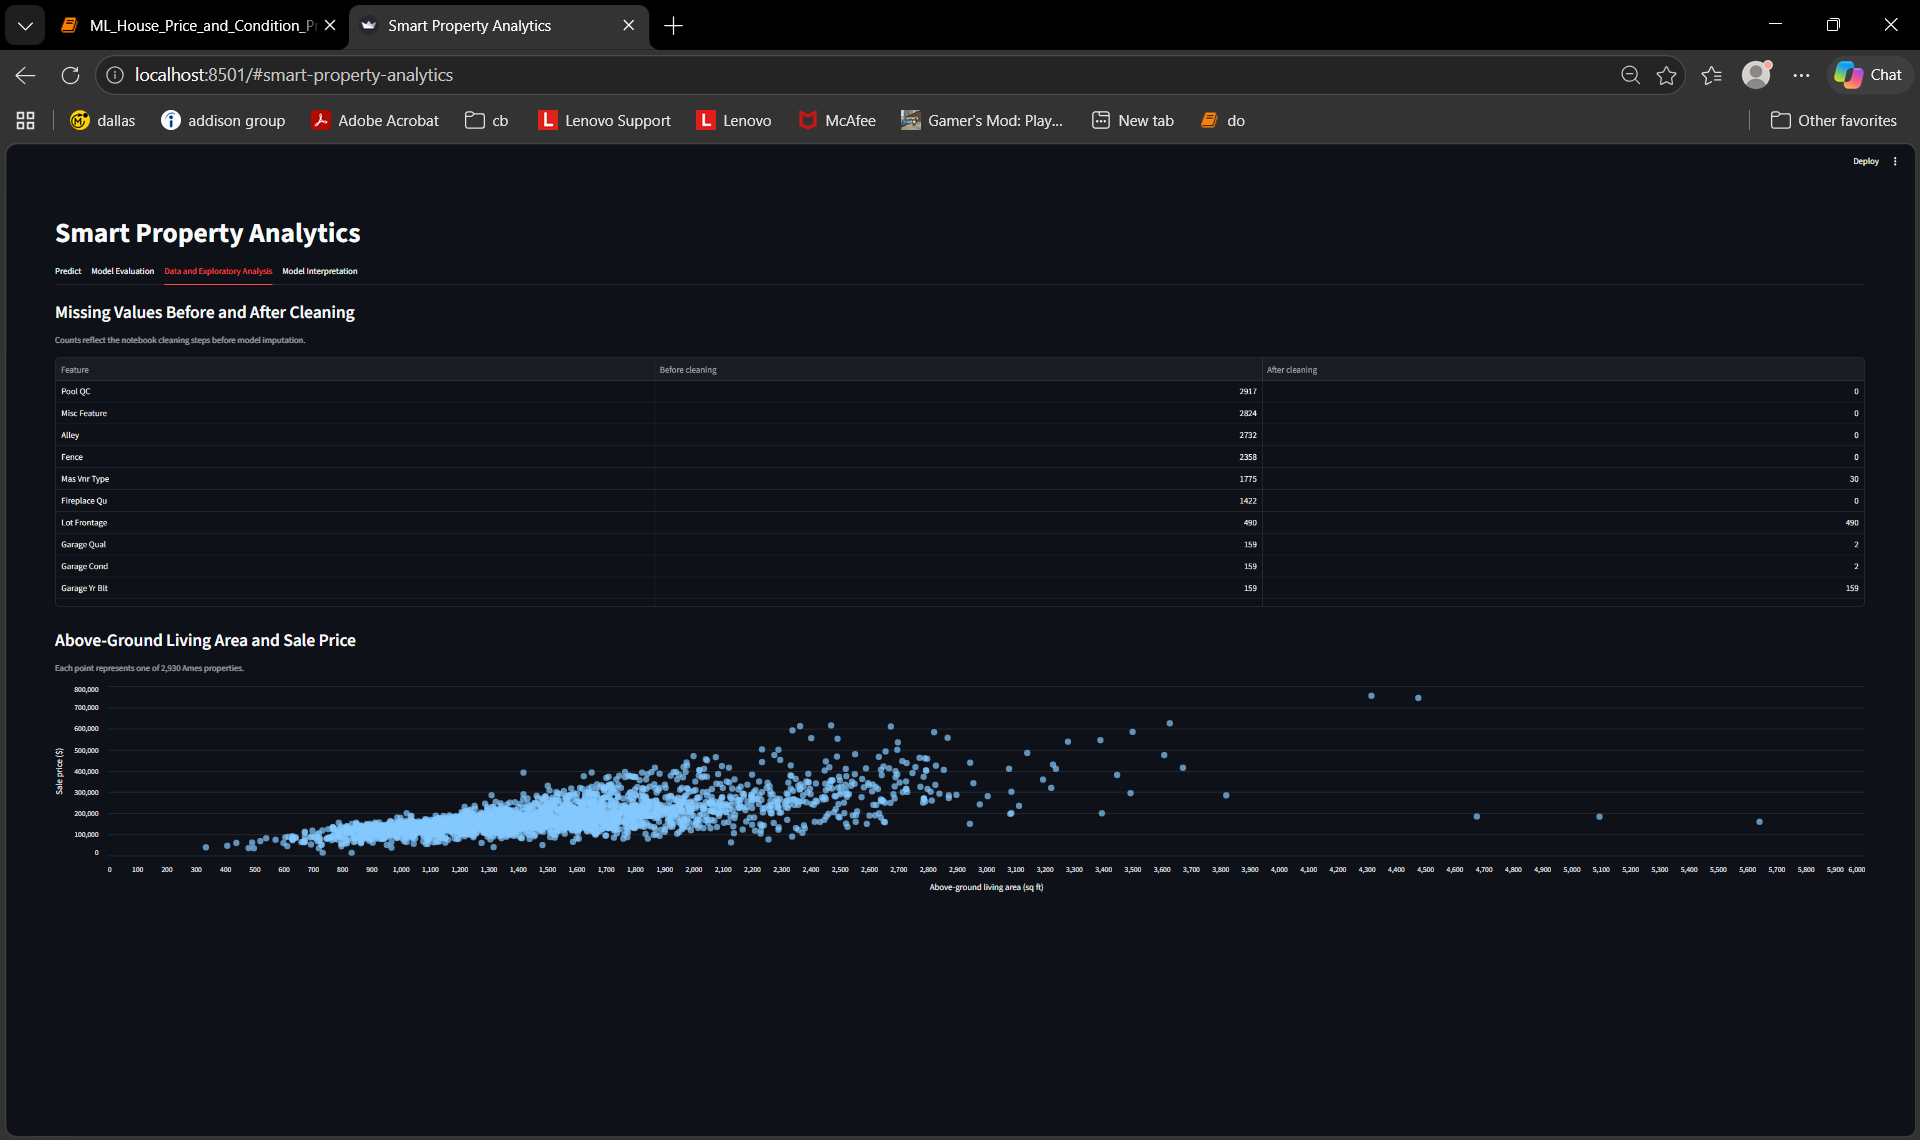

Explanation:
Pool QC shows before cleaning it was 2917 and after cleaning it is now 0
Lot Frontage shows 490 before and after cleaning. 
Scatter plot reports 2930 properties. 

### Adding the Model Interpretation Tab

In [47]:
# Exporting the interpretation results

# Reference
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html

# Saving the tables already calculated in the notebook.
interpretation_tables = {
    "price_feature_importance.csv": top_price_features,
    "condition_feature_importance.csv": top_condition_features,
    "example_house_shap.csv": top_shap,
}

for filename, table in interpretation_tables.items():
    table.to_csv(models_folder / filename, index=False)

print("Interpretation files saved in:", models_folder.resolve())

Interpretation files saved in: C:\Users\nyamb\models


In [48]:
# Adding the tab to app.py

# References
# https://docs.python.org/3/library/pathlib.html
# https://docs.streamlit.io/develop/api-reference/layout/st.tabs
# https://docs.streamlit.io/develop/api-reference/data/st.dataframe

from pathlib import Path

app_path = Path(r"C:\Users\nyamb\app.py")
app_code = app_path.read_text(encoding="utf-8")

old_tabs = '''prediction_tab, evaluation_tab, eda_tab = st.tabs(
    ["Predict", "Model Evaluation", "Data and Exploratory Analysis"]
)'''

new_tabs = '''prediction_tab, evaluation_tab, eda_tab, interpretation_tab = st.tabs(
    ["Predict", "Model Evaluation", "Data and Exploratory Analysis",
     "Model Interpretation"]
)'''

interpretation_section = '''
with interpretation_tab:
    sections = [
        (
            "Sale Price Feature Importance",
            "price_feature_importance.csv",
            "How much test MAE increased after shuffling each feature.",
            2,
        ),
        (
            "Property Condition Feature Importance",
            "condition_feature_importance.csv",
            "How much test macro F1 decreased after shuffling each feature.",
            4,
        ),
        (
            "SHAP Explanation for the Prefilled Property",
            "example_house_shap.csv",
            "Positive contributions raised the model estimate relative to its "
            "baseline. Negative contributions lowered it. The table shows "
            "the ten largest contributions by absolute value.",
            2,
        ),
    ]

    for title, filename, description, decimals in sections:
        st.subheader(title)
        st.caption(description)
        table_path = models_folder / filename

        if table_path.is_file():
            st.dataframe(pd.read_csv(table_path).round(decimals), hide_index=True)
        else:
            st.info(f"Run the notebook interpretation export to create {filename}.")
'''

# Add the section once and check the revised script before saving it.
if "with interpretation_tab:" in app_code:
    print("The Model Interpretation tab is already in app.py.")
elif app_code.count(old_tabs) != 1:
    raise ValueError("Run the Data and Exploratory Analysis tab update first.")
else:
    updated_code = app_code.replace(old_tabs, new_tabs, 1)
    updated_code = updated_code.rstrip() + "\n\n" + interpretation_section.lstrip()
    compile(updated_code, str(app_path), "exec")
    app_path.write_text(updated_code, encoding="utf-8")
    print("Updated:", app_path)

Updated: C:\Users\nyamb\app.py


Model interpretation results:
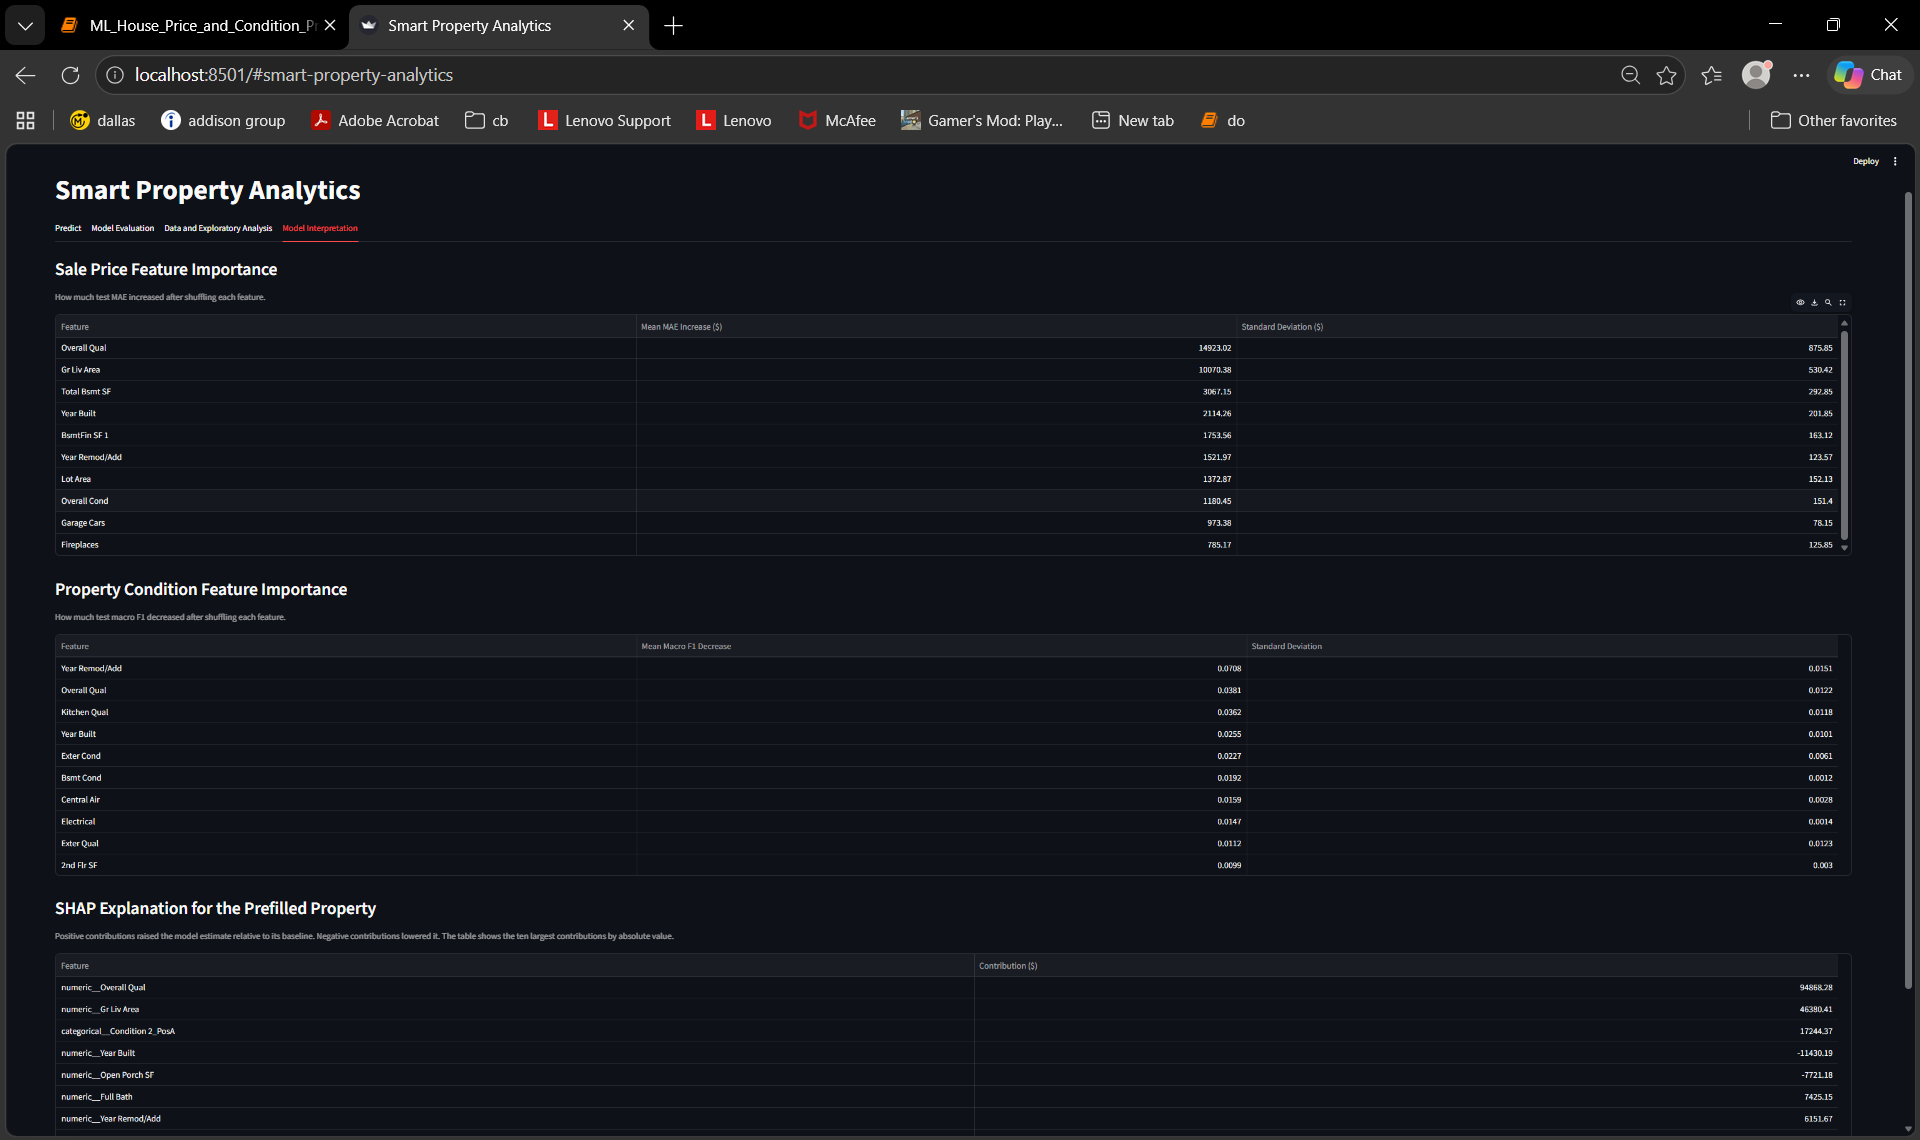

Explanation:

Overall Qual ranks first for sale price, Year Remod/Add ranks first for condition classification, and the prefilled property’s SHAP table shows a +$94,868.28 contribution from overall quality

# Project Conclusions

### Sale Price Prediction

XGBoost performed best among the four regression models in five-fold
cross-validation, with a mean absolute error of $14,473.45. On the 586
held-out properties, its mean absolute error was $15,024.27, its root mean
squared error was $26,976.56, and its R-squared was 0.8896.

Overall quality and above-ground living area were the two most important
features in the permutation analysis. They also made the largest positive
contributions in the SHAP explanation for the example house, which the
model estimated at $325,413.12. The house sold for $325,000.

### Property Condition Classification

Random Forest had the highest mean validation macro F1 score (0.6334)
among the three classifiers. On the held-out test set, it achieved 78.50%
accuracy and a macro F1 score of 0.6062. Remodel year, overall quality, and
kitchen quality ranked highest in its permutation importance analysis.

The classifier correctly identified 9 of the 34 properties in the High
category, giving it a recall of 26.47% for that group. It classified 17
of the remaining High properties as Medium and 8 as Low. This limits its
usefulness for flagging properties in the High category.

### Streamlit Dashboard


The Smart Property Analytics dashboard uses the saved XGBoost and Random
Forest pipelines to display a sale price estimate and a predicted condition
category from the property details entered in the form. The sample inputs
and screenshots above document how the dashboard was tested.

### Limitations and Future Improvements

The price model was evaluated on historical sales from Ames, Iowa. Evaluating it on more recent sales and in other locations would show how
well it transfers to different markets.
The condition categories were derived from the recorded overall condition rating. A future study could use independent inspection outcomes and
evaluate approaches that improve recall for the High category while tracking how many Low and Medium properties are incorrectly flagged.
